In [2]:
'''
Factor Analysis

By Anita Taylor

Date:  17/10/2023
'''

'\nFactor Analysis\n\nBy Anita Taylor\n\nDate:  17/10/2023\n'

In [3]:
'''
Sources:
https://www.datasklr.com/principal-component-analysis-and-factor-analysis/factor-analysis
https://www.earthinversion.com/geophysics/exploratory-factor-analysis/

https://www.datacamp.com/tutorial/introduction-factor-analysis
https://www.analyticsvidhya.com/blog/2020/10/dimensionality-reduction-using-factor-analysis-in-python/

https://www.datasklr.com/principal-component-analysis-and-factor-analysis/factor-analysis
https://www.kaggle.com/code/harrimansaragih/factor-analysis-of-airline-passenger-satisfaction
https://www.kaggle.com/code/francoisstamant/eda-and-factor-analysis

https://libguides.princeton.edu/factor#:~:text=the%20factor's%20dimensionality.-,A%20negative%20value%20indicates%20an%20inverse%20impact%20on%20the%20factor,variable%20in%20the%20factor%20model.
https://www.hawaii.edu/powerkills/UFA.HTM
chrome-extension://efaidnbmnnnibpcajpcglclefindmkaj/https://www.datavis.ca/courses/factor/efacfa-handout1-2x2.pdf


'''

'\nSources:\nhttps://www.datasklr.com/principal-component-analysis-and-factor-analysis/factor-analysis\nhttps://www.earthinversion.com/geophysics/exploratory-factor-analysis/\n\nhttps://www.datacamp.com/tutorial/introduction-factor-analysis\nhttps://www.analyticsvidhya.com/blog/2020/10/dimensionality-reduction-using-factor-analysis-in-python/\n\nhttps://www.datasklr.com/principal-component-analysis-and-factor-analysis/factor-analysis\nhttps://www.kaggle.com/code/harrimansaragih/factor-analysis-of-airline-passenger-satisfaction\n'

In [1]:
'''
Questions:


Should I use Promax not varimax rotation?  Due to slight correlation and large dataset?

Ask if I did the promax correctly - did I kick out the correct variables?
'''

'\nQuestions:\n\n\nShould I use Promax not varimax rotation?  Due to slight correlation and large dataset?\n\nAsk if I did the promax correctly - did I kick out the correct variables?\n'

In [2]:
!pip install factor_analyzer

In [3]:
!pip install pingouin


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import FactorAnalysis
from sklearn.preprocessing import StandardScaler
import seaborn as sns

from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity
from factor_analyzer.factor_analyzer import calculate_kmo
import pingouin as pg


In [8]:
'''
Input
'''
Datat = pd.read_csv('finalformofData.csv')
Datat.columns = Datat.columns.str.strip()
Datat['FD'] = Datat['PRECIPITATION']-Datat['Precip_Climatology']
Datat['HW'] = Datat['MAX_TEMP']-Datat['Tx_Climatology']
Datat['MT'] = Datat['MIN_TEMP']-Datat['Tn_Climatology']

def assign_group(aquifer_type):
    if aquifer_type in ['1a', '1b', '1c', '2', '3', '4a']:
        return '1'
    elif aquifer_type in ['4b', '4c']:
        return '2'
    elif aquifer_type in ['5a', '6a', '6b']:
        return '3'
    elif aquifer_type == '5b':
        return '4'
    else:
        return '5'
    
Datat['Aquifer Group'] = Datat['Aquifer Subtype'].apply(assign_group)
Datat = Datat.dropna()

DropDF1 = ['', 'Unnamed: 0.1', 'Unnamed: 0', 'LOCATION', 'History ID','Closest Longitude', 'Closest Latitude', 'Station ID', 'DATE_merged', 'Native ID', 'month', 'Station Name', 'EMS ID', 'Aquifer ID Number','Well Tag Number', 'year_month','Cd-T']
Datat = Datat.drop(DropDF1, axis=1, errors='ignore')

DropDF1b = ['Aquifer Subtype', 'Precip_Climatology', 'Tn_Climatology', 'Tx_Climatology' ]
Datat = Datat.drop(DropDF1b, axis=1, errors='ignore')

DropDF1c = ['OBSWELL']
Datat = Datat.drop(DropDF1c, axis=1, errors='ignore')



In [9]:
#Use a local Cartesian conversion to account for distance given it is very 'flat'.  Also should I reference Vancouver as the reference points?  They think they are the center of the world anyway

from math import radians, cos, sin, asin, sqrt

# Calculate the reference point
ref_latitude = Datat['LATITUTE'].mean()
ref_longitude = Datat['LONGITUDE'].mean()

# Convert latitudes and longitudes to radians
Datat['lat_rad'] = np.radians(Datat['LATITUTE'])  
Datat['lon_rad'] = np.radians(Datat['LONGITUDE'])
ref_lat_rad = np.radians(ref_latitude)
ref_lon_rad = np.radians(ref_longitude)

# Apply Haversine formula 
R = 6371 # Radius of earth in kilometers

# Calculate X distance (longitude)
Datat['x'] = R * np.arcsin(np.sqrt(np.sin((Datat['lon_rad'] - ref_lon_rad)/2)**2)) 

# Calculate Y distance (latitude)  
Datat['y'] = R * np.arcsin(np.sqrt(np.sin((Datat['lat_rad'] - ref_lat_rad)/2)**2))


DropDF2b = ['LONGITUDE','LATITUTE','lon_rad','lat_rad']
Datat = Datat.drop(DropDF2b, axis=1, errors='ignore')

#Start encoding it.  Will Finish it later
one_hot_df = pd.get_dummies(Datat['Aquifer Group'], prefix='Aquifer')
Datat = pd.concat([Datat, one_hot_df], axis=1)

#Decided to keep reference points the same
Datat['DATE'] = pd.to_datetime(Datat['DATE'])
Datawithtime = Datat.copy()

#Used "Time since event" - months since the first sampling time.  As this is sequencial, it has to be calculated in subsequent dataframes
Datat['Months_Since_First_Sample'] = ((Datat['DATE'] - Datat['DATE'].min()) / np.timedelta64(1, 'M')).round()
DropDF2a = ['DATE']
Datat = Datat.drop(DropDF2a, axis=1, errors='ignore')

Datat.columns

Index(['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Chlrid:D', 'Fe-T', 'Mn-T',
       'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'pH', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT',
       'Aquifer Group', 'x', 'y', 'Aquifer_1', 'Aquifer_2', 'Aquifer_3',
       'Months_Since_First_Sample'],
      dtype='object')

In [10]:
Datat.columns

Index(['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Chlrid:D', 'Fe-T', 'Mn-T',
       'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'pH', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT',
       'Aquifer Group', 'x', 'y', 'Aquifer_1', 'Aquifer_2', 'Aquifer_3',
       'Months_Since_First_Sample'],
      dtype='object')

In [11]:
Datat.shape

(985, 29)

In [12]:
'''
Handling Outliers

Notes:  
To prevent more outlier removal, use MAD score.  ID datat style.  Will not to Mahalanobis method due to complexity

Decided to use threshold score instead.  MAD scores takes away from metals being past the drinking water standard and SWI values

Source:
https://stats.stackexchange.com/questions/591853/interquartile-range-finding-more-than-10-times-outliers-than-zscore#:~:text=Yes%20%2D%20using%20the%20IQR%20method,will%20find%20lots%20of%20outliers.
https://saturncloud.io/blog/how-to-detect-and-exclude-outliers-in-a-pandas-dataframe/#:~:text=The%20IQR%20can%20be%20calculated,can%20be%20considered%20an%20outlier.
https://www.analyticsvidhya.com/blog/2021/05/detecting-and-treating-outliers-treating-the-odd-one-out/
'''

def replace_outliers_with_iqr(dataset, k=1.5):
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        Q1 = cleaned_dataset[col].quantile(0.25)
        Q3 = cleaned_dataset[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_threshold = Q1 - k * IQR
        upper_threshold = Q3 + k * IQR
        cleaned_dataset.loc[cleaned_dataset[col] < lower_threshold, col] = lower_threshold
        cleaned_dataset.loc[cleaned_dataset[col] > upper_threshold, col] = upper_threshold
    return cleaned_dataset

#You can adjust the `k` parameter to control how aggressive the outlier detection is. The default value of 1.5 corresponds to approximately ±2.7σ or 99.3% coverage if the data is normally distributed.

numeric_cols1 = ['pH', 'As-T', 'Ca-T', 'Chlrid:D', 'Fe-T', 'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Specific Conductance', 'Sulfat:D', 'K--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT',  'Alkalinity Total 4.5', 'Hardness Total (T)', 'Residue Filterable 1.0u']
#Numeric_cols1a = ['Alkalinity Total 4.5', 'Hardness Total (T)','Residue Filterable 1.0u']
cleaned_dataset_array1 = replace_outliers_with_iqr(Datat[numeric_cols1], 1.5)
Datat[numeric_cols1] = cleaned_dataset_array1

def replace_loweroutliers_with_iqr(dataset, k=1.5):
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        Q1 = cleaned_dataset[col].quantile(0.25)
        Q3 = cleaned_dataset[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_threshold = Q1 - k * IQR
        cleaned_dataset.loc[cleaned_dataset[col] < lower_threshold, col] = lower_threshold
    return cleaned_dataset
numeric_cols1a = ['U--T']
cleaned_dataset_array1a = replace_outliers_with_iqr(Datat[numeric_cols1a], 1.5)
Datat[numeric_cols1a] = cleaned_dataset_array1a

def replace_outliers_with_threshold(dataset, threshold_multiplier=3):
    """
    Replace outliers in a dataset with the threshold value based on the Median Absolute Deviation (MAD).

    Parameters:
    - dataset: DataFrame containing the dataset.
    - threshold_multiplier: Multiple of the MAD to be used as the threshold (default: 3).

    Returns:
    - cleaned_dataset: DataFrame with outliers replaced by the threshold.
    """
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        col_values = cleaned_dataset[col].values
        median = np.median(col_values)
        mad = np.median(np.abs(col_values - median))
        lower_threshold = median - threshold_multiplier * mad
        upper_threshold = median + threshold_multiplier * mad
        outliers = (col_values - median) > upper_threshold
        cleaned_dataset.loc[outliers, col] = upper_threshold
        outliers = (col_values - median) < lower_threshold
        cleaned_dataset.loc[outliers, col] = lower_threshold
    return cleaned_dataset


In [13]:
'''
Scaling

Source:
https://scikit-learn.org/stable/modules/preprocessing.html
https://stats.stackexchange.com/questions/402470/how-can-i-use-scaling-and-log-transforming-together

https://stackoverflow.com/questions/60998512/how-to-scale-all-columns-except-last-column
https://stackoverflow.com/questions/62997793/apply-standarization-to-all-columns-except-one-in-pandas
'''

from sklearn.preprocessing import PowerTransformer

# Create a PowerTransformer object
pt = PowerTransformer(method='yeo-johnson')

# Define the column names you want to transform
cols_to_transform = ['As-T', 'Ca-T', 'Chlrid:D', 'Fe-T', 'Mn-T', 'N.Kjel:T',
       'P--T', 'Pb-T', 'Specific Conductance', 'Sulfat:D', 'pH', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT' , 'Alkalinity Total 4.5', 'Hardness Total (T)', 'Residue Filterable 1.0u']
# Apply the transformation to the specified columns
Datat[cols_to_transform] = pt.fit_transform(Datat[cols_to_transform])

In [19]:
'''
encoding 

# encode this to numbers instead.   Make it a different dataset
source:
'''
DatatHot = Datat.drop(columns='Aquifer Group')
DatatHot.shape

(985, 28)

In [21]:
'''
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
Datat[cols_to_transform] = scaler.fit_transform(Datat[cols_to_transform])
'''

'\nfrom sklearn.preprocessing import MinMaxScaler\nscaler = MinMaxScaler()\nDatat[cols_to_transform] = scaler.fit_transform(Datat[cols_to_transform])\n'

In [14]:
#CHECK ADEQUACY .
#Bartlett.  Over 5 samples per variable so not trustworthy 
#p-value should be 0 (statistically sig.)
# Select only the continuous columns
#Create functions for Barlette and KMO

from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity

def analyze_continuous_data(df):
    # Select continuous columns
    continuous_columns = df.columns[df.dtypes == 'float64']
    df_continuous = df[continuous_columns]

    # Run Bartlett's test on the continuous data
    chi_square_value, p_value = calculate_bartlett_sphericity(df_continuous)
    print(f"Bartlett's test results:\nChi-square value - {chi_square_value}\nP-value - {p_value}")

    # Run Kaiser-Meyer-Olkin (KMO) test
    kmo_all, kmo_model = calculate_kmo(df_continuous)
    print(f"\nKaiser-Meyer-Olkin test results:\nOverall MSA - {kmo_model}")

    # Print MSA for each variable
    print("\nMSA for each variable:")
    for col, msa in zip(continuous_columns, kmo_all):
        print(f"{col}: {msa}")

In [15]:
'''
Factor Analysis 1st step

'''
from factor_analyzer import FactorAnalyzer
import matplotlib.pyplot as plt
import numpy as np

def perform_factor_analysis(data, n_factors=None):
    # Fit the FactorAnalyzer to the data
    fa = FactorAnalyzer(n_factors=n_factors, rotation=None)
    fa.fit(data)

    # Calculate eigenvalues
    ev, _ = fa.get_eigenvalues()

    # Calculate the sum of all eigenvalues and the sum of eigenvalues greater than 1
    total_ev_sum = ev.sum()
    ev_gt1_sum = ev[ev > 1].sum()

    # Print the number of eigenvalues greater than 1
    num_eigenvalues_gt1 = (ev > 1).sum()
    print(f"Number of eigenvalues greater than 1: {num_eigenvalues_gt1}")

    # Print the eigenvalues
    print("Eigenvalues: ", ev)

    # Print the sum of eigenvalues greater than 1
    print(f"Sum of eigenvalues greater than 1: {ev_gt1_sum}")

    # Print the ratio of the sum of eigenvalues greater than 1 to the total sum of eigenvalues
    print(f"Sum of eigenvalues > 1 / total sum of eigenvalues: {ev_gt1_sum / total_ev_sum}")

    # Create a scree plot
    plt.scatter(range(1, data.shape[1]+1), ev)
    plt.plot(range(1, data.shape[1]+1), ev)
    plt.title('Scree Plot')
    plt.xlabel('Factors')
    plt.ylabel('Eigenvalue')
    plt.grid(True) # Add major gridlines

    # Set minor ticks on the x-axis
    ax = plt.gca()
    ax.set_xticks(np.arange(1, data.shape[1] + 1), minor=True)

    # Add minor gridlines
    plt.grid(which='minor', color='#999999', linestyle='-', alpha=0.2)

    plt.axhline(y=1, color='r', linestyle='--')
    plt.show()

In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from factor_analyzer import FactorAnalyzer
from matplotlib import gridspec

import numpy as np

def perform_factor_analysis_and_plot(data, n_factors, data_name):
    fa = FactorAnalyzer(n_factors=n_factors, rotation='varimax')
    fa.fit(data)

    # Getting the factor loadings
    loadings = fa.loadings_

    # Getting communalities, uniqueness
    communalities = fa.get_communalities()
    uniqueness = fa.get_uniquenesses()
    
    # Getting variance
    ss_loadings, prop_variance, cum_variances = fa.get_factor_variance()
    
    # Calculate communalities, uniqueness, and total variance
    var_check = np.vstack((fa.get_communalities(), fa.get_uniquenesses(),np.array(fa.get_communalities() + fa.get_uniquenesses()))).tolist()

    # Combine into a single dataframe
    fa_df = pd.DataFrame(loadings, index=data.columns, columns=[f'Factor {i+1}' for i in range(n_factors)])
    fa_df['Communality'] = communalities
    fa_df['Uniqueness'] = uniqueness

    # Create DataFrame for variances
    var_df = pd.DataFrame(index=[f'Factor {i+1}' for i in range(n_factors)], 
                          data={'SS Loadings': ss_loadings,
                                'Proportional Variance': prop_variance,
                                'Cumulative Variance': cum_variances})

    # Combine factor analysis results and variances into a single DataFrame
    combined_df = pd.concat([fa_df, var_df])

    # Define filename for the CSV and PNG files
    csv_filename = f'Stats/{data_name}_FactorAnalysis_{n_factors}.csv'
    png_filename = f'Figures/{data_name}_FactorAnalysis_{n_factors}.png'

    # Save combined DataFrame to CSV
    combined_df.to_csv(csv_filename)

    # Create GridSpec
    #gs = gridspec.GridSpec(2, 1, height_ratios=[3, 1])

    # Create a figure
    fig = plt.figure(figsize=(10, 15))
    fig.suptitle('Factor Analysis, Communalities, Uniqueness and Total Variance ', fontsize=14, y=0.92)
    
    gs = gridspec.GridSpec(6, 1, height_ratios=[6,.75,.5, 4,.75,.5]) #Adjust the height_ratios as needed

    ax1 = fig.add_subplot(gs[0])
    sns.heatmap(loadings.T, cmap='coolwarm', center=0, square=False, linewidths=.2, cbar=False, annot=False, annot_kws={"fontsize":10}, xticklabels=data.columns, yticklabels=[f'Factor {i+1}' for i in range(n_factors)], ax=ax1)
    ax1.set_xlabel('Dataset Variables')
    ax1.set_ylabel('Factors', rotation=90)
    ax1.set_yticklabels(ax1.get_yticklabels(), rotation=360) # Rotate y-labels

    # Spacer row between colorbar and next heatmap
    spacer1 = fig.add_subplot(gs[1])
    spacer1.axis('off')  # hide the spacer row
    
    # Add colorbar for ax1 as independent axes
    cax1 = fig.add_subplot(gs[2])
    cb1 = fig.colorbar(ax1.collections[0], cax=cax1, orientation="horizontal")

    ax2 = fig.add_subplot(gs[3])
    sns.heatmap(var_check, cmap='RdBu', center=0, square=False, linewidths=.2, cbar=False, annot=False, annot_kws={"fontsize":10}, yticklabels=['Communality', 'Uniqueness', 'Total Variance'], xticklabels=data.columns, ax=ax2)
    ax2.set_title('Communality, Uniqueness and Total Variance', fontsize=12)
    ax2.set_xlabel('Dataset Variables')
    ax2.set_yticklabels(ax2.get_yticklabels(), rotation=360)
 
    spacer1 = fig.add_subplot(gs[4])
    spacer1.axis('off')  # hide the spacer row
    
    cax2 = fig.add_subplot(gs[5])
    cb2 = plt.colorbar(ax2.collections[0], cax=cax2, orientation="horizontal")
    
    fig.subplots_adjust(hspace=0.8)
    plt.savefig(png_filename)
    plt.show()


In [17]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from factor_analyzer import FactorAnalyzer
from matplotlib import gridspec

import numpy as np

def perform_factor_analysis_and_plotOBS(data, n_factors, data_name):
    fa = FactorAnalyzer(n_factors=n_factors, rotation='Oblimin')
    fa.fit(data)

    # Getting the factor loadings
    loadings = fa.loadings_

    # Getting communalities, uniqueness
    communalities = fa.get_communalities()
    uniqueness = fa.get_uniquenesses()
    
    # Getting variance
    ss_loadings, prop_variance, cum_variances = fa.get_factor_variance()
    
    # Calculate communalities, uniqueness, and total variance
    var_check = np.vstack((fa.get_communalities(), fa.get_uniquenesses(),np.array(fa.get_communalities() + fa.get_uniquenesses()))).tolist()

    # Combine into a single dataframe
    fa_df = pd.DataFrame(loadings, index=data.columns, columns=[f'Factor {i+1}' for i in range(n_factors)])
    fa_df['Communality'] = communalities
    fa_df['Uniqueness'] = uniqueness

    # Create DataFrame for variances
    var_df = pd.DataFrame(index=[f'Factor {i+1}' for i in range(n_factors)], 
                          data={'SS Loadings': ss_loadings,
                                'Proportional Variance': prop_variance,
                                'Cumulative Variance': cum_variances})

    # Combine factor analysis results and variances into a single DataFrame
    combined_df = pd.concat([fa_df, var_df])

    # Define filename for the CSV and PNG files
    csv_filename = f'Stats/{data_name}_FactorAnalysisOblimin_{n_factors}.csv'
    png_filename = f'Figures/{data_name}_FactorAnalysisOblimin_{n_factors}.png'

    # Save combined DataFrame to CSV
    combined_df.to_csv(csv_filename)

    # Create GridSpec
    #gs = gridspec.GridSpec(2, 1, height_ratios=[3, 1])

    # Create a figure
    fig = plt.figure(figsize=(10, 15))
    fig.suptitle('Factor Analysis, Communalities, Uniqueness and Total Variance ', fontsize=14, y=0.92)
    
    gs = gridspec.GridSpec(6, 1, height_ratios=[6,.75,.5, 4,.75,.5]) #Adjust the height_ratios as needed

    ax1 = fig.add_subplot(gs[0])
    sns.heatmap(loadings.T, cmap='coolwarm', center=0, square=False, linewidths=.2, cbar=False, annot=False, annot_kws={"fontsize":10}, xticklabels=data.columns, yticklabels=[f'Factor {i+1}' for i in range(n_factors)], ax=ax1)
    ax1.set_xlabel('Dataset Variables')
    ax1.set_ylabel('Factors', rotation=90)
    ax1.set_yticklabels(ax1.get_yticklabels(), rotation=360) # Rotate y-labels

    # Spacer row between colorbar and next heatmap
    spacer1 = fig.add_subplot(gs[1])
    spacer1.axis('off')  # hide the spacer row
    
    # Add colorbar for ax1 as independent axes
    cax1 = fig.add_subplot(gs[2])
    cb1 = fig.colorbar(ax1.collections[0], cax=cax1, orientation="horizontal")

    ax2 = fig.add_subplot(gs[3])
    sns.heatmap(var_check, cmap='RdBu', center=0, square=False, linewidths=.2, cbar=False, annot=False, annot_kws={"fontsize":10}, yticklabels=['Communality', 'Uniqueness', 'Total Variance'], xticklabels=data.columns, ax=ax2)
    ax2.set_title('Communality, Uniqueness and Total Variance', fontsize=12)
    ax2.set_xlabel('Dataset Variables')
    ax2.set_yticklabels(ax2.get_yticklabels(), rotation=360)
 
    spacer1 = fig.add_subplot(gs[4])
    spacer1.axis('off')  # hide the spacer row
    
    cax2 = fig.add_subplot(gs[5])
    cb2 = plt.colorbar(ax2.collections[0], cax=cax2, orientation="horizontal")
    
    fig.subplots_adjust(hspace=0.8)
    plt.savefig(png_filename)
    plt.show()
    


In [20]:
analyze_continuous_data(DatatHot)

Bartlett's test results:
Chi-square value - 15496.648194906047
P-value - 0.0

Kaiser-Meyer-Olkin test results:
Overall MSA - 0.7317915704460185

MSA for each variable:
Alkalinity Total 4.5: 0.90408373394274
As-T: 0.8152468027567632
Ca-T: 0.7543260112555925
Chlrid:D: 0.800793098862211
Fe-T: 0.7259348955197934
Mn-T: 0.636664363838817
N.Kjel:T: 0.7522541775343401
P--T: 0.5350203236032333
Pb-T: 0.6517099860409996
Residue Filterable 1.0u: 0.8832643557485756
Specific Conductance: 0.839562972727259
Sulfat:D: 0.9191124149433219
pH: 0.761146137390538
Hardness Total (T): 0.7647650431149975
K--T: 0.8183637727050909
U--T: 0.8936412213888966
PRECIPITATION: 0.6982479826459658
MIN_TEMP: 0.4703846567266276
MAX_TEMP: 0.4706984314703794
FD: 0.405709097596006
HW: 0.43375941745652047
MT: 0.3527730137432191
x: 0.5689147713059234
y: 0.8002871390462649
Months_Since_First_Sample: 0.6773852052713596


Number of eigenvalues greater than 1: 9
Eigenvalues:  [ 5.95711236e+00  3.07329292e+00  2.60806581e+00  2.00359255e+00
  1.95670709e+00  1.70059650e+00  1.25756127e+00  1.17757482e+00
  1.12544423e+00  9.81600681e-01  9.16736592e-01  7.25886988e-01
  6.48441803e-01  6.01852726e-01  5.55404388e-01  4.21611869e-01
  3.84507883e-01  3.42833902e-01  3.10515208e-01  2.91427668e-01
  2.54922401e-01  2.12936153e-01  1.78533928e-01  1.36598190e-01
  7.67893137e-02  5.88886283e-02  4.05641320e-02 -2.33244519e-15]
Sum of eigenvalues greater than 1: 20.859947546425815
Sum of eigenvalues > 1 / total sum of eigenvalues: 0.7449981266580645


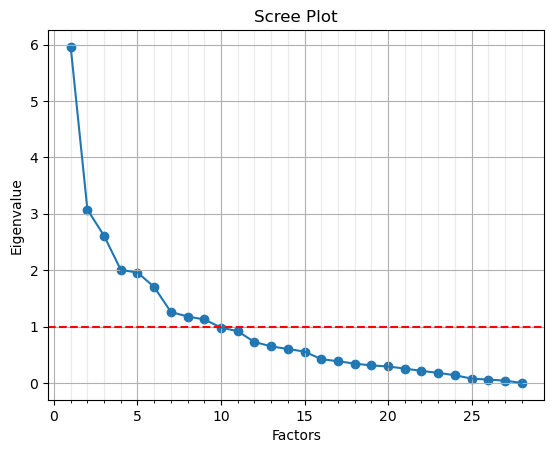

<Figure size 640x480 with 0 Axes>

In [21]:
perform_factor_analysis(DatatHot,n_factors=28)
plt.savefig('Figures/1stfulldatascreeredo.png')

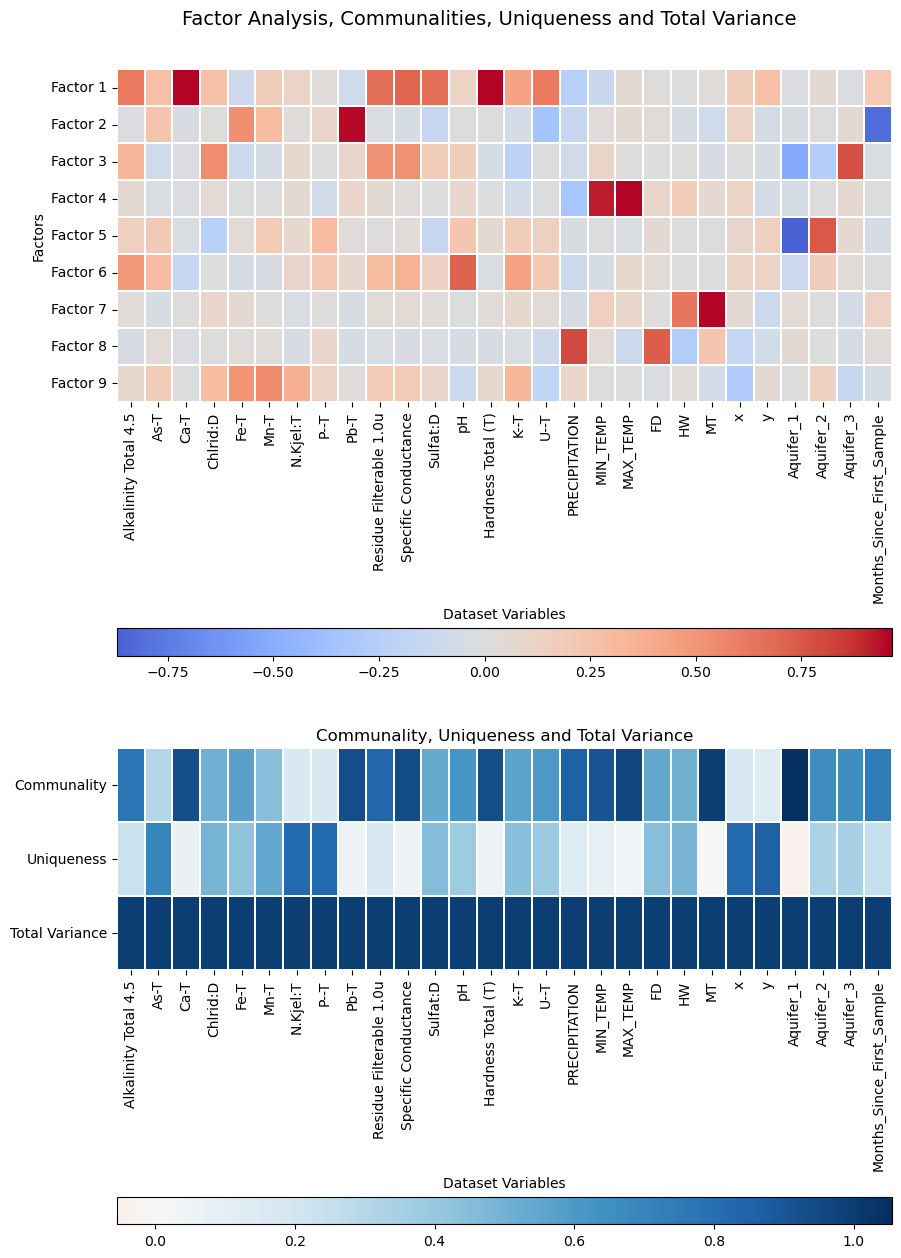

In [22]:
perform_factor_analysis_and_plot(DatatHot, n_factors=9, data_name='DatatHot')

In [ ]:
DropDF4ai = ['FD', 'MT', 'HW','Hardness Total (T)']

### For The Second part of the analysis 

In [23]:
DropDF4a = ['FD', 'MT', 'HW','Hardness Total (T)']
DatatHotNoBias= DatatHot.drop(DropDF4a, axis=1, errors='ignore')
analyze_continuous_data(DatatHotNoBias)

Bartlett's test results:
Chi-square value - 11553.24427544417
P-value - 0.0

Kaiser-Meyer-Olkin test results:
Overall MSA - 0.761172725476521

MSA for each variable:
Alkalinity Total 4.5: 0.8988990974547786
As-T: 0.800806285020268
Ca-T: 0.7978210420776263
Chlrid:D: 0.7988312884937324
Fe-T: 0.7412618442611136
Mn-T: 0.6567866740286642
N.Kjel:T: 0.736170333208779
P--T: 0.5770929701927165
Pb-T: 0.6459232243351118
Residue Filterable 1.0u: 0.8679794061494268
Specific Conductance: 0.8185567807459964
Sulfat:D: 0.9003707047277408
pH: 0.6920242503997244
K--T: 0.841090123685231
U--T: 0.8669526147510036
PRECIPITATION: 0.7705139714207814
MIN_TEMP: 0.4959985011962334
MAX_TEMP: 0.5107698207915554
x: 0.5825978925006875
y: 0.7796696696978047
Months_Since_First_Sample: 0.6661888923304723


In [42]:
DatatHotNoBias.shape

(985, 24)

Number of eigenvalues greater than 1: 7
Eigenvalues:  [ 5.46726597e+00  3.05927685e+00  2.47726712e+00  1.96961972e+00
  1.87146352e+00  1.28465276e+00  1.08199648e+00  9.62039682e-01
  7.97655157e-01  7.75389680e-01  6.82308755e-01  6.19245532e-01
  5.45960923e-01  4.03274053e-01  3.85585700e-01  3.65163349e-01
  3.33703172e-01  2.53839633e-01  2.18520367e-01  1.67740778e-01
  1.39131124e-01  7.76506336e-02  6.12490527e-02 -2.19142705e-15]
Sum of eigenvalues greater than 1: 17.21154241092083
Sum of eigenvalues > 1 / total sum of eigenvalues: 0.7171476004550346


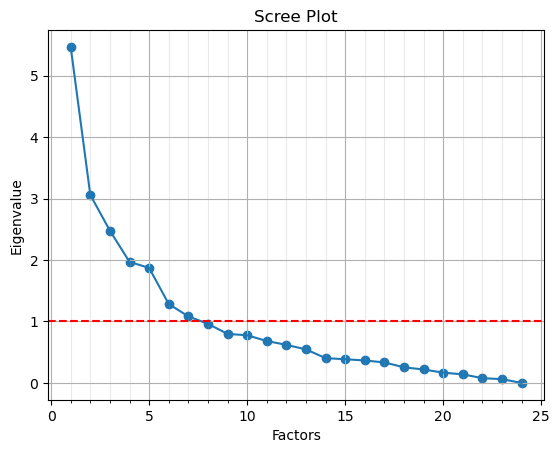

<Figure size 640x480 with 0 Axes>

In [43]:
perform_factor_analysis(DatatHotNoBias, n_factors=24)
plt.savefig('Figures/1stfulldatascreeNOMTFDHW.png')

In [97]:
perform_factor_analysis_and_plot(DatatHotNoBias, n_factors=7, data_name='DatatHotNoBias')

PermissionError: [Errno 13] Permission denied: 'Stats/DatatHotNoBias_FactorAnalysis_7.csv'

# Check For errors here

In [18]:
DropDF7a = ['K--T', 'x',  'pH', 'y', 'P--T', 'N.Kjel:T','As-T', 'PRECIPITATION']
DatatHotNoBiasP2 = DatatHotNoBias.drop(DropDF7a, axis=1, errors='ignore')

DropDF7b = []

DatatHotNoBiasP2.shape

(985, 16)

In [43]:
#DatatHotNoBiasP2 = DatatHotNoBiasP2.applymap(lambda x: x**2)


In [19]:
analyze_continuous_data(DatatHotNoBiasP2)

Bartlett's test results:
Chi-square value - 8758.157727076246
P-value - 0.0

Kaiser-Meyer-Olkin test results:
Overall MSA - 0.7481418094277115

MSA for each variable:
Alkalinity Total 4.5: 0.8552539790183379
Ca-T: 0.8419666530966708
Chlrid:D: 0.8048422854092722
Fe-T: 0.7309044481119921
Mn-T: 0.5751100945573854
Pb-T: 0.6459660740273914
Residue Filterable 1.0u: 0.8408955950352314
Specific Conductance: 0.7865855584001339
Sulfat:D: 0.9343374254766265
U--T: 0.8432426462910834
MIN_TEMP: 0.4717219881822794
MAX_TEMP: 0.4779615066018742
Months_Since_First_Sample: 0.6642664687939616


Number of eigenvalues greater than 1: 5
Eigenvalues:  [ 4.55996732e+00  2.73803388e+00  1.93606516e+00  1.65191482e+00
  1.47298213e+00  8.83177406e-01  7.61678357e-01  4.28131836e-01
  4.06862402e-01  3.68526117e-01  3.00347744e-01  1.79996294e-01
  1.54208692e-01  8.36262296e-02  7.44816047e-02 -1.97620281e-15]
Sum of eigenvalues greater than 1: 12.358963317029882
Sum of eigenvalues > 1 / total sum of eigenvalues: 0.7724352073143674


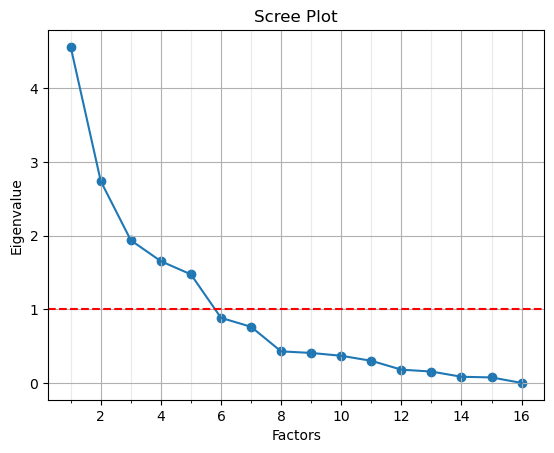

<Figure size 640x480 with 0 Axes>

In [20]:
perform_factor_analysis(DatatHotNoBiasP2, n_factors=16)
plt.savefig('Figures/screeDatatHotNoBiasP2.png')

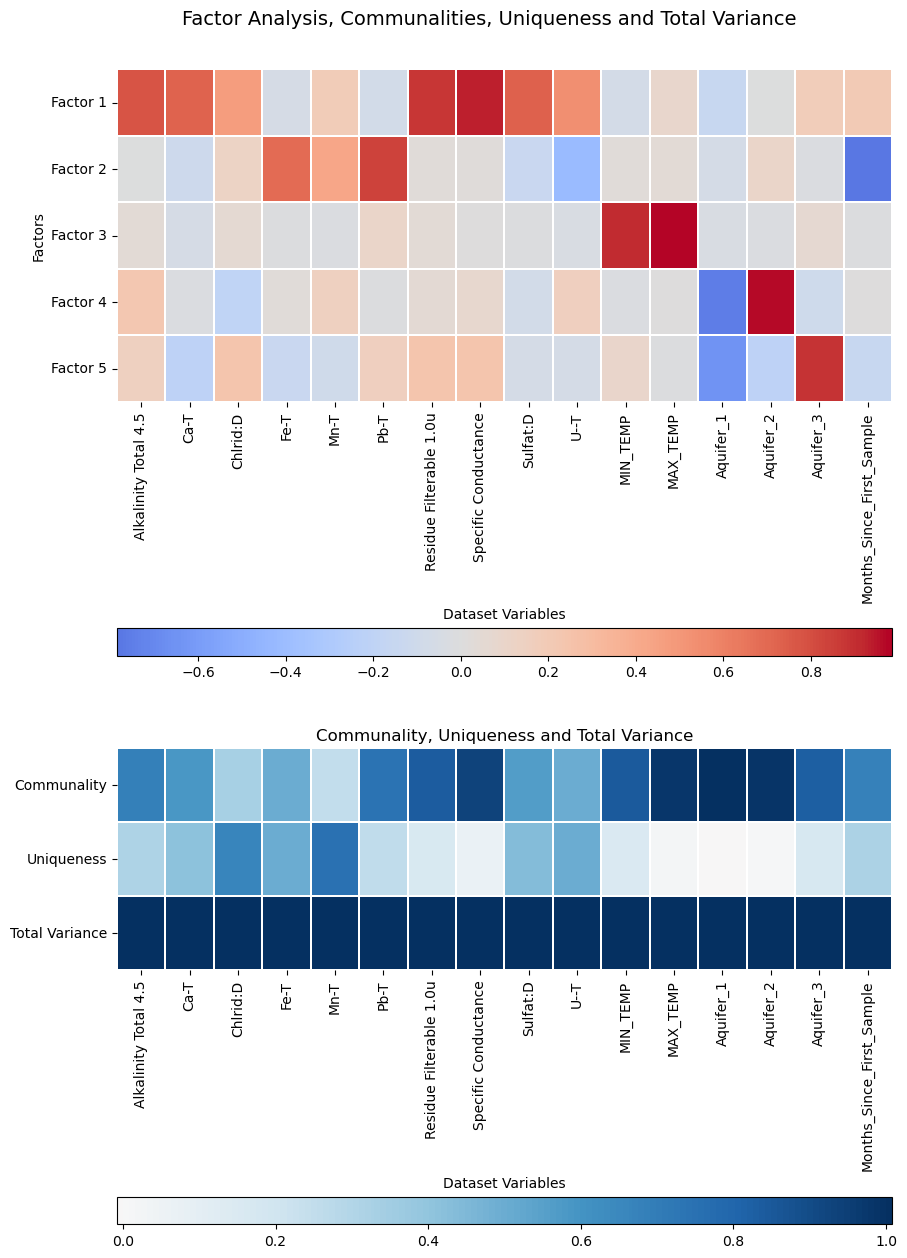

In [21]:


perform_factor_analysis_and_plot(DatatHotNoBiasP2, n_factors=5, data_name='DatatHotNoBiasP2')

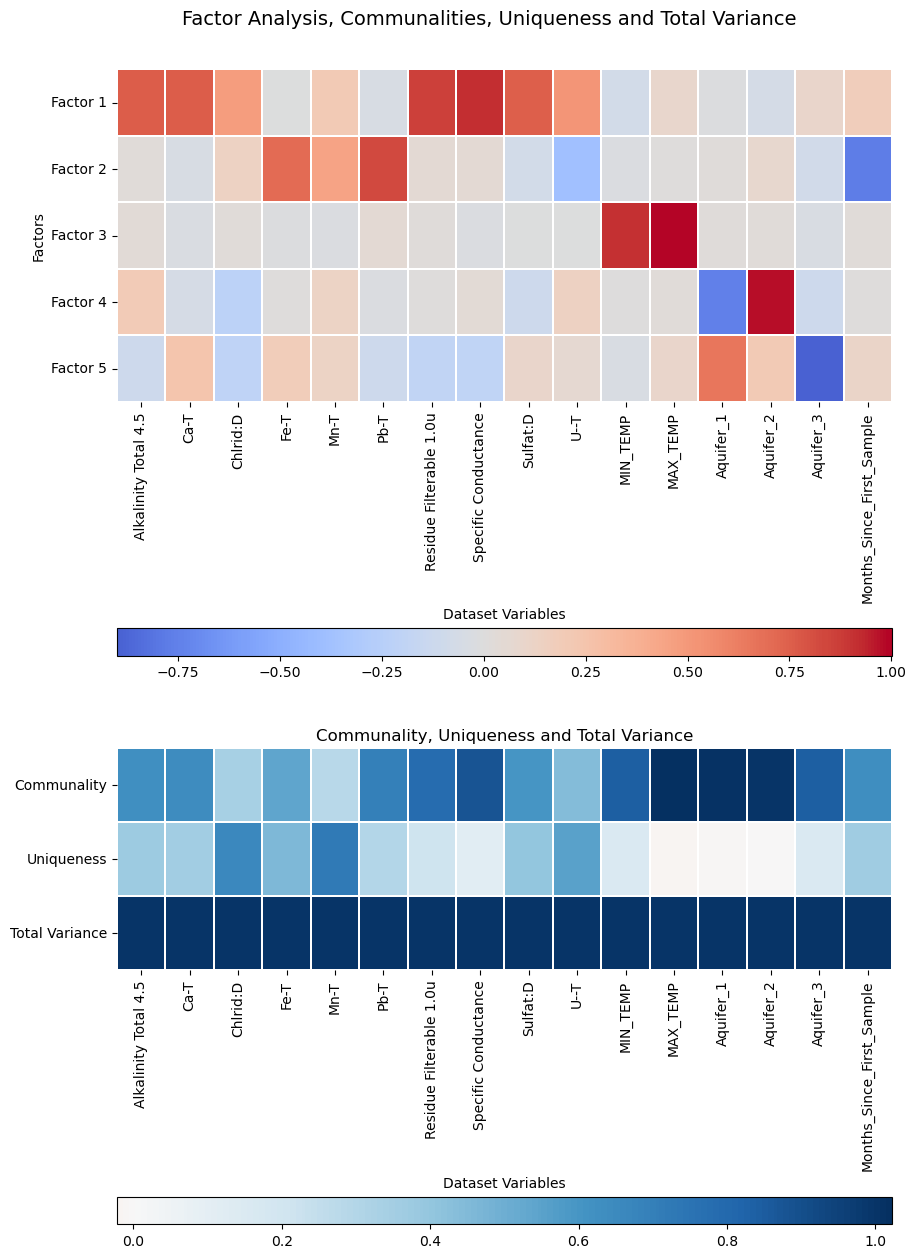

In [22]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from factor_analyzer import FactorAnalyzer
from matplotlib import gridspec

import numpy as np

def perform_factor_analysis_and_plotpro(data, n_factors, data_name):
    fa = FactorAnalyzer(n_factors=n_factors, rotation='Promax')
    fa.fit(data)

    # Getting the factor loadings
    loadings = fa.loadings_

    # Getting communalities, uniqueness
    communalities = fa.get_communalities()
    uniqueness = fa.get_uniquenesses()
    
    # Getting variance
    ss_loadings, prop_variance, cum_variances = fa.get_factor_variance()
    
    # Calculate communalities, uniqueness, and total variance
    var_check = np.vstack((fa.get_communalities(), fa.get_uniquenesses(),np.array(fa.get_communalities() + fa.get_uniquenesses()))).tolist()

    # Combine into a single dataframe
    fa_df = pd.DataFrame(loadings, index=data.columns, columns=[f'Factor {i+1}' for i in range(n_factors)])
    fa_df['Communality'] = communalities
    fa_df['Uniqueness'] = uniqueness

    # Create DataFrame for variances
    var_df = pd.DataFrame(index=[f'Factor {i+1}' for i in range(n_factors)], 
                          data={'SS Loadings': ss_loadings,
                                'Proportional Variance': prop_variance,
                                'Cumulative Variance': cum_variances})

    # Combine factor analysis results and variances into a single DataFrame
    combined_df = pd.concat([fa_df, var_df])

    # Define filename for the CSV and PNG files
    csv_filename = f'Stats/{data_name}_FactorAnalysisPromax_{n_factors}.csv'
    png_filename = f'Figures/{data_name}_FactorAnalysisPromax_{n_factors}.png'

    # Save combined DataFrame to CSV
    combined_df.to_csv(csv_filename)

    # Create GridSpec
    #gs = gridspec.GridSpec(2, 1, height_ratios=[3, 1])

    # Create a figure
    fig = plt.figure(figsize=(10, 15))
    fig.suptitle('Factor Analysis, Communalities, Uniqueness and Total Variance ', fontsize=14, y=0.92)
    
    gs = gridspec.GridSpec(6, 1, height_ratios=[6,.75,.5, 4,.75,.5]) #Adjust the height_ratios as needed

    ax1 = fig.add_subplot(gs[0])
    sns.heatmap(loadings.T, cmap='coolwarm', center=0, square=False, linewidths=.2, cbar=False, annot=False, annot_kws={"fontsize":10}, xticklabels=data.columns, yticklabels=[f'Factor {i+1}' for i in range(n_factors)], ax=ax1)
    ax1.set_xlabel('Dataset Variables')
    ax1.set_ylabel('Factors', rotation=90)
    ax1.set_yticklabels(ax1.get_yticklabels(), rotation=360) # Rotate y-labels

    # Spacer row between colorbar and next heatmap
    spacer1 = fig.add_subplot(gs[1])
    spacer1.axis('off')  # hide the spacer row
    
    # Add colorbar for ax1 as independent axes
    cax1 = fig.add_subplot(gs[2])
    cb1 = fig.colorbar(ax1.collections[0], cax=cax1, orientation="horizontal")

    ax2 = fig.add_subplot(gs[3])
    sns.heatmap(var_check, cmap='RdBu', center=0, square=False, linewidths=.2, cbar=False, annot=False, annot_kws={"fontsize":10}, yticklabels=['Communality', 'Uniqueness', 'Total Variance'], xticklabels=data.columns, ax=ax2)
    ax2.set_title('Communality, Uniqueness and Total Variance', fontsize=12)
    ax2.set_xlabel('Dataset Variables')
    ax2.set_yticklabels(ax2.get_yticklabels(), rotation=360)
 
    spacer1 = fig.add_subplot(gs[4])
    spacer1.axis('off')  # hide the spacer row
    
    cax2 = fig.add_subplot(gs[5])
    cb2 = plt.colorbar(ax2.collections[0], cax=cax2, orientation="horizontal")
    
    fig.subplots_adjust(hspace=0.8)
    plt.savefig(png_filename)
    plt.show()
    
perform_factor_analysis_and_plotpro(DatatHotNoBiasP2, n_factors=5, data_name='DatatHotNoBiasP2')

In [23]:
'''
Residue matric

Source:
https://www.geo.fu-berlin.de/en/v/soga-py/Advanced-statistics/Multivariate-Approaches/Factor-Analysis/A-Simple-Example-of-Factor-Analysis-in-Python/index.html
'''

from factor_analyzer import FactorAnalyzer
import numpy as np
import matplotlib.pyplot as plt

fa = FactorAnalyzer(n_factors=5, rotation='Promax')
fa.fit(DatatHotNoBiasP2)

# the word 'lambda' is reserved for a python-operator, so we use the underscore at the end
lambda_ = fa.loadings_

uniqueness = fa.get_uniquenesses()

# Create a zero matrix with the same number of variables as the data
psi = np.zeros((DatatHotNoBiasP2.shape[1], DatatHotNoBiasP2.shape[1]))

# Fill the diagonal of the zero matrix with uniqueness values
np.fill_diagonal(psi, uniqueness)

# Compute the observed correlation matrix
s = np.corrcoef(DatatHotNoBiasP2, rowvar=False)

# Compute the predicted correlation matrix
sigma = np.matmul(lambda_, lambda_.T) + psi

# Compute the residuals
residuals = s - sigma

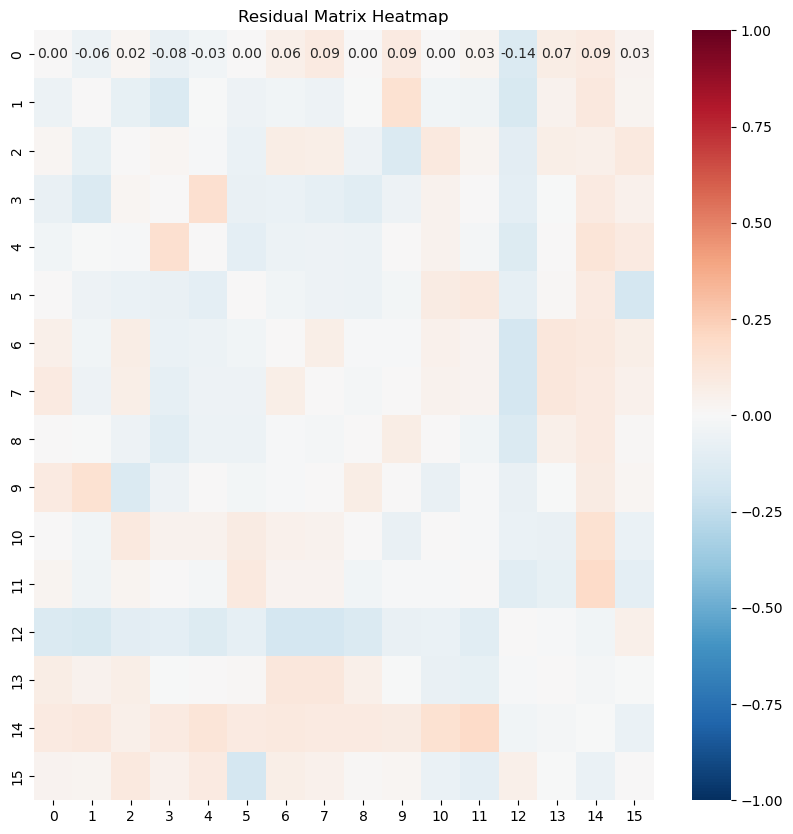

In [24]:
import seaborn as sns

# Plot heatmap of residuals
plt.figure(figsize=(10, 10))
sns.heatmap(residuals, cmap='RdBu_r', vmin=-1, vmax=1, annot=True, fmt=".2f")
plt.title("Residual Matrix Heatmap")
plt.savefig('Figures/ResidualMatrixHeatmap.png')
plt.show()

In [154]:
DataHotP2factors = pd.read_csv("Stats/DatatHotNoBiasP2_FactorAnalysisPromax_7.csv")
DataHotP2factors.columns

Index(['Unnamed: 0', 'Factor 1', 'Factor 2', 'Factor 3', 'Factor 4',
       'Factor 5', 'Factor 6', 'Factor 7', 'Communality', 'Uniqueness',
       'SS Loadings', 'Proportional Variance', 'Cumulative Variance'],
      dtype='object')

In [168]:
DatatHotNoBiasP2.columns

Index(['Alkalinity Total 4.5', 'Ca-T', 'Chlrid:D', 'Mn-T', 'Pb-T',
       'Residue Filterable 1.0u', 'Specific Conductance', 'Sulfat:D', 'U--T',
       'MIN_TEMP', 'MAX_TEMP', 'x', 'Aquifer_1', 'Aquifer_2', 'Aquifer_3',
       'Months_Since_First_Sample'],
      dtype='object')

In [200]:
F1 = DatatHotNoBiasP2[['Residue Filterable 1.0u', 'Alkalinity Total 4.5','Chlrid:D', 'Specific Conductance', 'Sulfat:D']]
F3 = DatatHotNoBiasP2[['MIN_TEMP', 'MAX_TEMP']]


CADataHot = DatatHotNoBiasP2.copy()
columns_to_reverse = ['Months_Since_First_Sample','Chlrid:D']  # replace with your actual column names

    
F2 = CADataHot[['Pb-T','Months_Since_First_Sample']] #do I take the negative factors as well?F3
F6 = CADataHot[['U--T', 'x','Chlrid:D']]

F4 = DatatHotNoBiasP2[['Aquifer_2', 'Aquifer_1']]
F5 = CADataHot[['Aquifer_3', 'Aquifer_1']]


In [172]:
factor1_alpha = pg.cronbach_alpha(F1)
print(factor1_alpha)

(0.8822562532086253, array([0.87 , 0.893]))


In [179]:
factor3_alpha = pg.cronbach_alpha(F3)
print(factor3_alpha)

(0.942954326087794, array([0.935, 0.95 ]))


# Part that needs to be checked ends

In [76]:
'''
Individual Metals 
'''
DropDF5a = ['Mn-T', 'Pb-T', 'U--T']
DatatHotAs = DatatHotNoBias.drop(DropDF5a, axis=1, errors='ignore')

DropDF5b = ['As-T', 'Pb-T', 'U--T']
DatatHotMn = DatatHotNoBias.drop(DropDF5b, axis=1, errors='ignore')

DropDF5c = ['As-T', 'Mn-T', 'U--T']
DatatHotPb = DatatHotNoBias.drop(DropDF5c, axis=1, errors='ignore')


DropDF5d = ['As-T', 'Mn-T', 'Pb-T']
DatatHotU = DatatHotNoBias.drop(DropDF5d, axis=1, errors='ignore')


In [45]:
DatatHotAs.shape

(985, 21)

In [46]:
analyze_continuous_data(DatatHotAs)

Bartlett's test results:
Chi-square value - 9243.174327354998
P-value - 0.0

Kaiser-Meyer-Olkin test results:
Overall MSA - 0.7383240196980778

MSA for each variable:
Alkalinity Total 4.5: 0.8991704939186934
As-T: 0.7155956815349779
Ca-T: 0.8272601221868453
Chlrid:D: 0.7213128256548975
Fe-T: 0.4759370726786634
N.Kjel:T: 0.74692578117824
P--T: 0.559829272456189
Residue Filterable 1.0u: 0.876186413800634
Specific Conductance: 0.8120629892368
Sulfat:D: 0.9126514411167753
pH: 0.6770639902873195
K--T: 0.8157436435567677
PRECIPITATION: 0.7842000284119592
MIN_TEMP: 0.47791608861917556
MAX_TEMP: 0.48861430498927155
x: 0.5295552435548463
y: 0.6508846234392981
Months_Since_First_Sample: 0.5865827813295734


Number of eigenvalues greater than 1: 7
Eigenvalues:  [ 5.04323262e+00  2.41297958e+00  2.36085595e+00  1.87131754e+00
  1.53039063e+00  1.12243436e+00  1.03617324e+00  8.87158050e-01
  7.67683055e-01  7.43660716e-01  6.31652594e-01  5.50558902e-01
  4.43469309e-01  3.99466553e-01  3.55213338e-01  2.75372884e-01
  2.27772349e-01  1.98269993e-01  8.03282782e-02  6.20100634e-02
 -1.83319958e-15]
Sum of eigenvalues greater than 1: 15.37738391574542
Sum of eigenvalues > 1 / total sum of eigenvalues: 0.7322563769402581


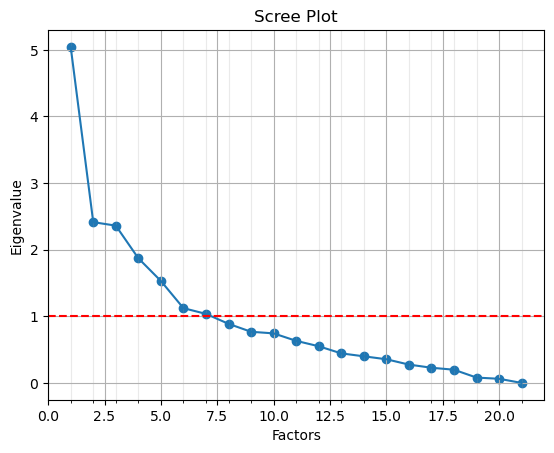

<Figure size 640x480 with 0 Axes>

In [130]:
perform_factor_analysis(DatatHotAs, n_factors=21)
plt.savefig('Figures/DatatHotAsScreeplot.png')

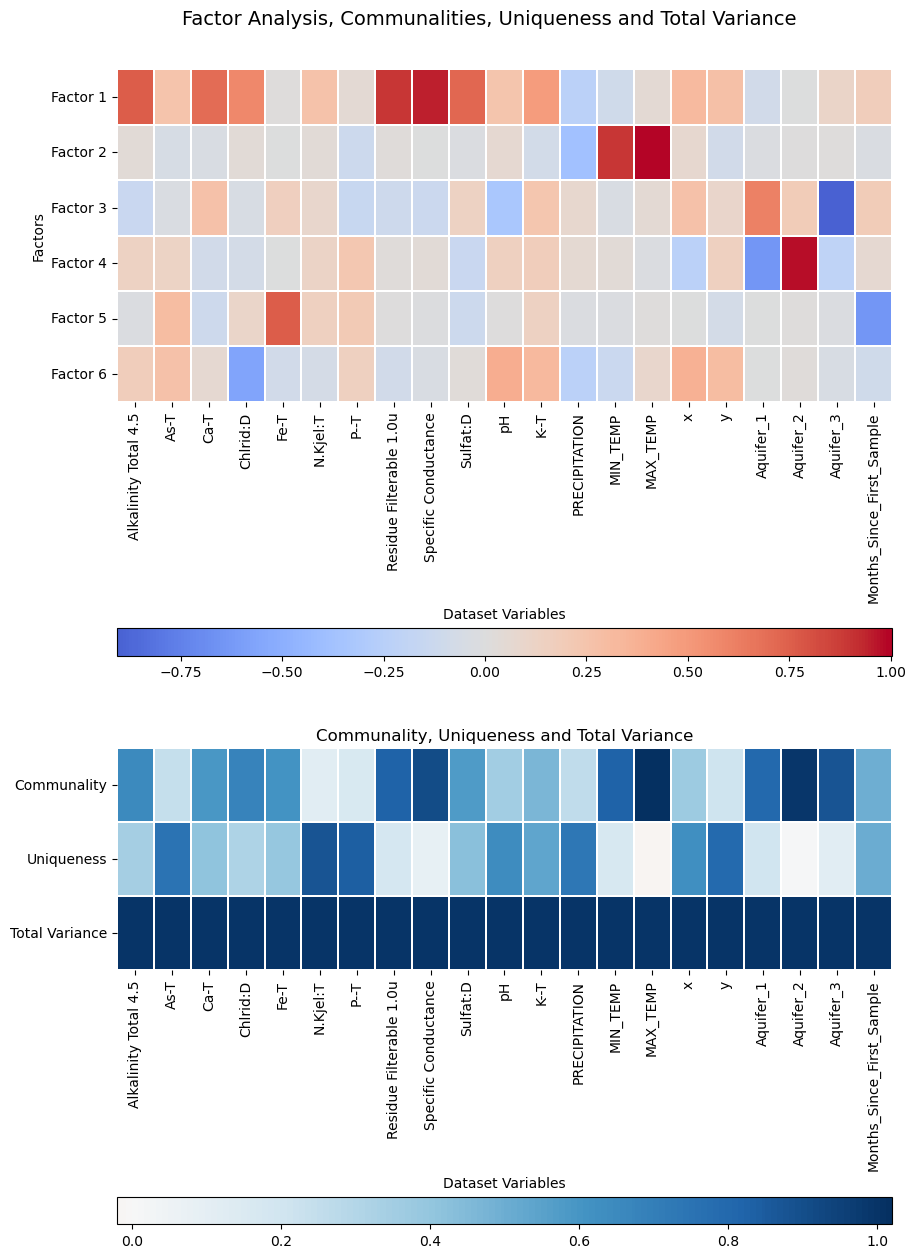

In [142]:
perform_factor_analysis_and_plotOBS(DatatHotAs, n_factors=6, data_name='DatatHotAs')

In [75]:
analyze_continuous_data(DatatHotMn)

Bartlett's test results:
Chi-square value - 9352.758071902863
P-value - 0.0

Kaiser-Meyer-Olkin test results:
Overall MSA - 0.7288928442117084

MSA for each variable:
Alkalinity Total 4.5: 0.8984052653311193
Ca-T: 0.8083000721042713
Chlrid:D: 0.7268887494241342
Fe-T: 0.508060160759072
Mn-T: 0.5670158592061747
N.Kjel:T: 0.7388917766715181
P--T: 0.4609203475769797
Residue Filterable 1.0u: 0.8707616977157823
Specific Conductance: 0.8124758955072675
Sulfat:D: 0.921138233557546
pH: 0.6701093567741082
K--T: 0.8175475648568824
PRECIPITATION: 0.7807616322288237
MIN_TEMP: 0.47564817627410255
MAX_TEMP: 0.4872577616929795
x: 0.5355130000819502
y: 0.6613097256898285
Months_Since_First_Sample: 0.6196960341158622


Number of eigenvalues greater than 1: 6
Eigenvalues:  [ 4.96381067e+00  2.40353128e+00  2.36252214e+00  1.88692207e+00
  1.74316036e+00  1.09368090e+00  9.59412768e-01  9.13191172e-01
  7.54907779e-01  7.40546438e-01  6.33328145e-01  5.15899249e-01
  4.61006511e-01  3.91445797e-01  3.55552355e-01  2.60143081e-01
  2.26948596e-01  1.91840490e-01  8.05106654e-02  6.16395367e-02
 -1.94644375e-15]
Sum of eigenvalues greater than 1: 14.453627415617682
Sum of eigenvalues > 1 / total sum of eigenvalues: 0.6882679721722704


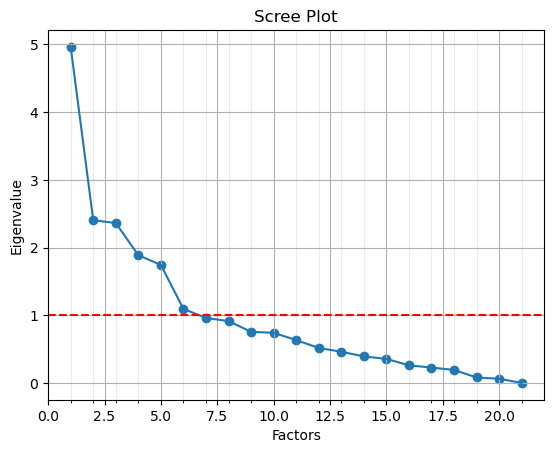

<Figure size 640x480 with 0 Axes>

In [131]:
perform_factor_analysis(DatatHotMn, n_factors=21)
plt.savefig('Figures/DatatHotMnScreeplot.png')

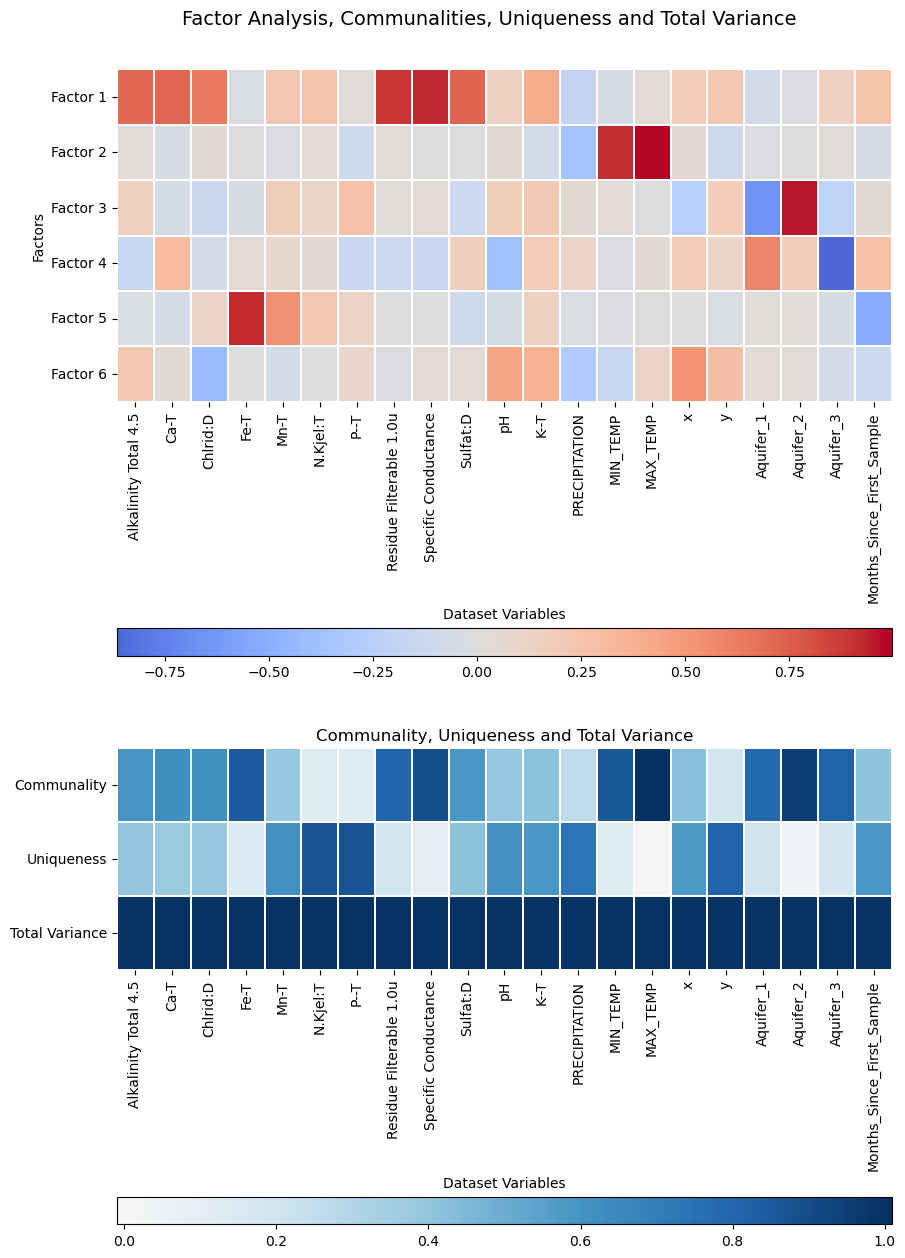

In [143]:
perform_factor_analysis_and_plotOBS(DatatHotMn, n_factors=6, data_name='DatatHotMn')

In [80]:
analyze_continuous_data(DatatHotPb)

Bartlett's test results:
Chi-square value - 10171.700220553756
P-value - 0.0

Kaiser-Meyer-Olkin test results:
Overall MSA - 0.7295662625880021

MSA for each variable:
Alkalinity Total 4.5: 0.8971200669335341
Ca-T: 0.8385438894072145
Chlrid:D: 0.7277983552388306
Fe-T: 0.7375613479674956
N.Kjel:T: 0.751007945653778
P--T: 0.4430292544253055
Pb-T: 0.5880788112281847
Residue Filterable 1.0u: 0.8629656987854465
Specific Conductance: 0.8068487836521868
Sulfat:D: 0.9135145966311524
pH: 0.6639351412184425
K--T: 0.8064122407200924
PRECIPITATION: 0.8041651146237717
MIN_TEMP: 0.47822748231750994
MAX_TEMP: 0.4931857815194969
x: 0.5561244843121589
y: 0.6387375284361316
Months_Since_First_Sample: 0.6016122398694883


Number of eigenvalues greater than 1: 6
Eigenvalues:  [ 4.93431579e+00  2.71338080e+00  2.28177060e+00  1.91173288e+00
  1.77666408e+00  1.15910243e+00  9.56373414e-01  8.93012273e-01
  7.45920252e-01  7.35622818e-01  5.61605179e-01  5.19919276e-01
  4.11895109e-01  3.76257900e-01  3.03230307e-01  2.30494560e-01
  2.03045834e-01  1.45191577e-01  7.89227305e-02  6.15421950e-02
 -2.05382871e-15]
Sum of eigenvalues greater than 1: 14.77696657533747
Sum of eigenvalues > 1 / total sum of eigenvalues: 0.7036650750160699


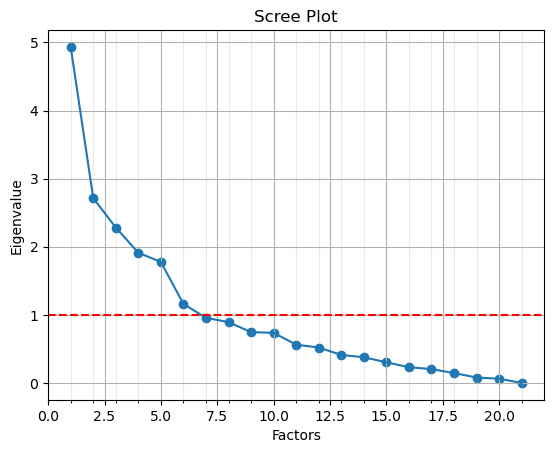

<Figure size 640x480 with 0 Axes>

In [132]:
perform_factor_analysis(DatatHotPb, n_factors=21)
plt.savefig('Figures/DatatHotPbScreeplot.png')

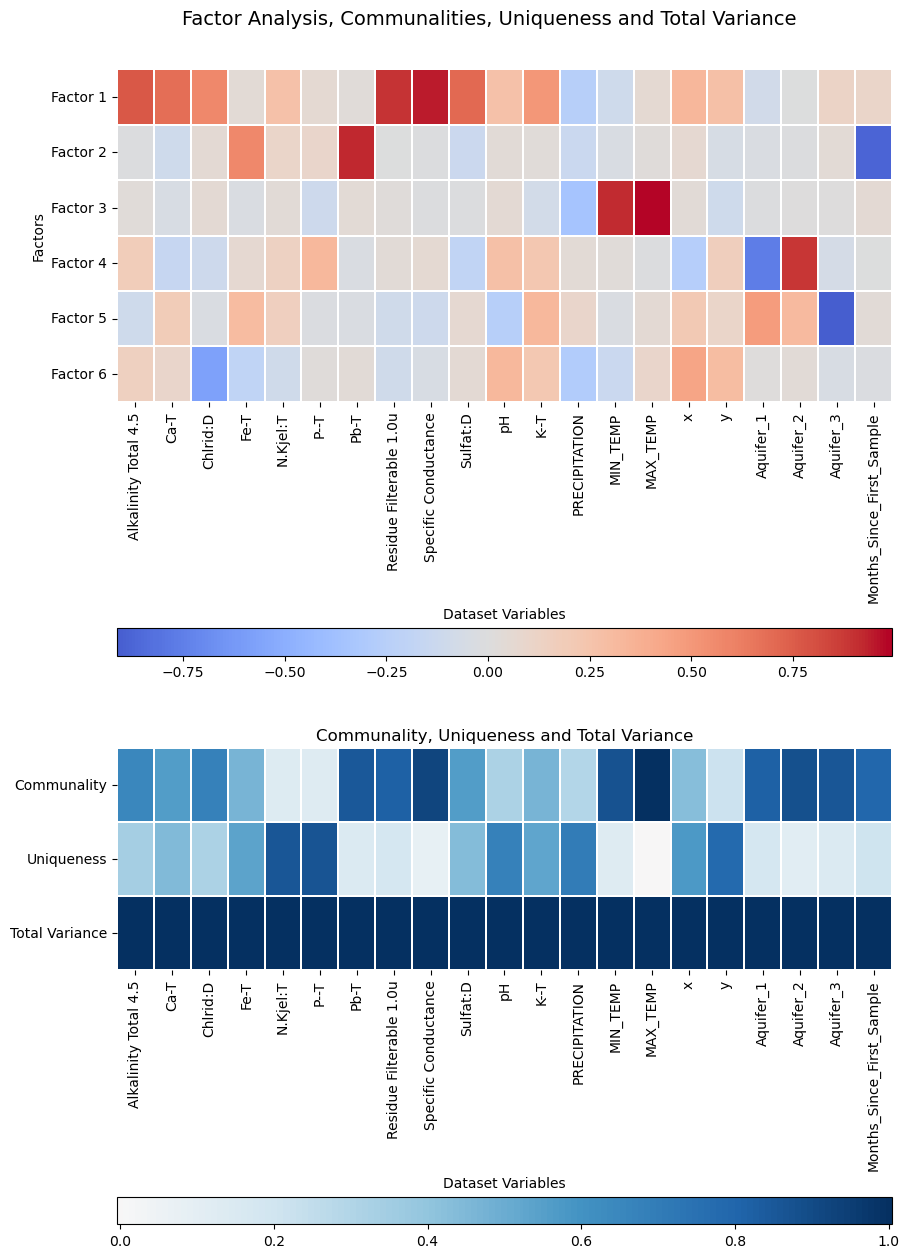

In [144]:
perform_factor_analysis_and_plotOBS(DatatHotPb, n_factors=6, data_name='DatatHotPb')

In [81]:
analyze_continuous_data(DatatHotU)

Bartlett's test results:
Chi-square value - 9727.265720552403
P-value - 0.0

Kaiser-Meyer-Olkin test results:
Overall MSA - 0.7601480145308284

MSA for each variable:
Alkalinity Total 4.5: 0.9096871799258252
Ca-T: 0.8433149294268434
Chlrid:D: 0.7472717038938981
Fe-T: 0.5682631724794461
N.Kjel:T: 0.7574950702419844
P--T: 0.4272474661481612
Residue Filterable 1.0u: 0.8786515220146991
Specific Conductance: 0.820301715015271
Sulfat:D: 0.9246870453899095
pH: 0.6723144629744024
K--T: 0.8266147091085377
U--T: 0.8479176580818809
PRECIPITATION: 0.7754251210229599
MIN_TEMP: 0.48118946839325905
MAX_TEMP: 0.4885141710792296
x: 0.6108477869057835
y: 0.6974816245988098
Months_Since_First_Sample: 0.6039478238116178


Number of eigenvalues greater than 1: 6
Eigenvalues:  [ 5.32464515e+00  2.48890984e+00  2.24417949e+00  1.87835409e+00
  1.63456096e+00  1.07722729e+00  9.53745874e-01  8.86605458e-01
  7.61395292e-01  7.36856092e-01  5.77446179e-01  4.95531104e-01
  4.11789223e-01  3.67039316e-01  3.37655430e-01  2.89939788e-01
  2.20535090e-01  1.71516904e-01  8.00992770e-02  6.19681492e-02
 -2.01814191e-15]
Sum of eigenvalues greater than 1: 14.647876823237794
Sum of eigenvalues > 1 / total sum of eigenvalues: 0.6975179439637045


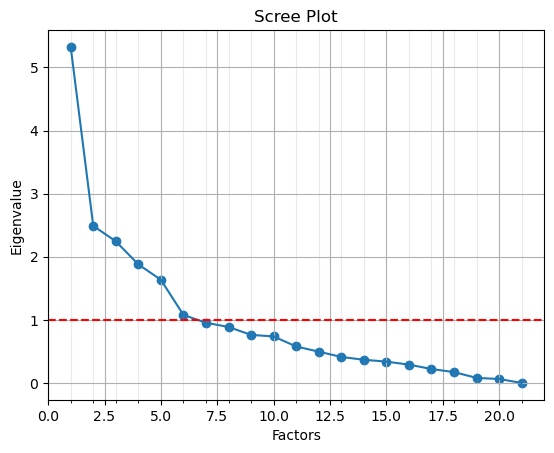

<Figure size 640x480 with 0 Axes>

In [133]:
perform_factor_analysis(DatatHotU, n_factors=21)
plt.savefig('Figures/DatatHotUScreeplot.png')

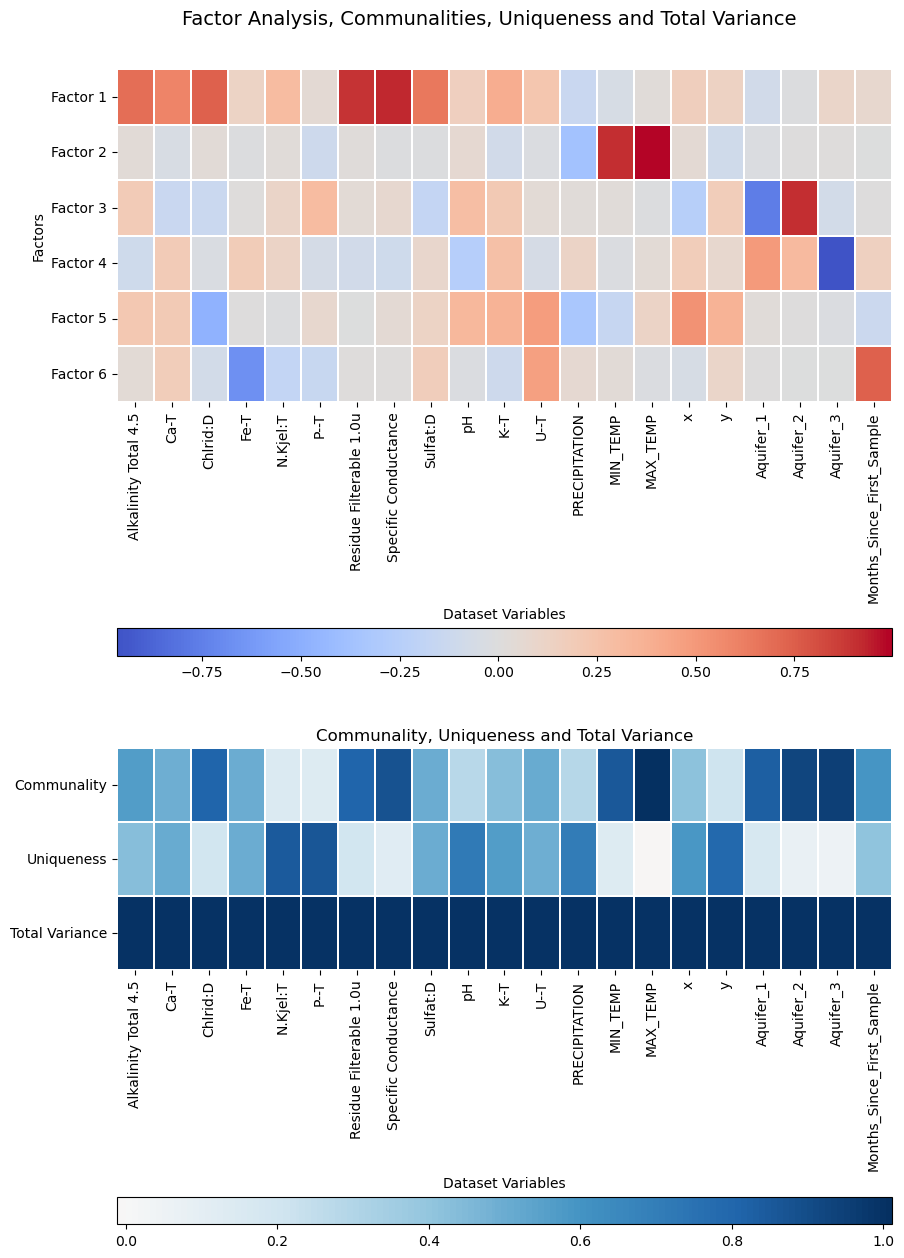

In [145]:
perform_factor_analysis_and_plotOBS(DatatHotU, n_factors=6, data_name='DatatHotU')

In [103]:
DatatHotNoBias.columns

Index(['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Chlrid:D', 'Fe-T', 'Mn-T',
       'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'pH', 'K--T', 'U--T',
       'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'x', 'y', 'Aquifer_1',
       'Aquifer_2', 'Aquifer_3', 'Months_Since_First_Sample'],
      dtype='object')

In [ ]:
'''
Drought, Flood and Temperature Factors

Source:
https://www.statisticshowto.com/kaiser-meyer-olkin/

Not enough samples
'''

In [104]:
DataHotTP = DatatHotNoBias[['As-T', 'Mn-T', 'Pb-T', 'N.Kjel:T', 'U--T',
       'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'x', 'y', 'Aquifer_1',
       'Aquifer_2', 'Aquifer_3', 'Months_Since_First_Sample']]
DataHotTP.shape

(985, 14)

In [105]:
analyze_continuous_data(DataHotTP)

Bartlett's test results:
Chi-square value - 4474.71568413503
P-value - 0.0

Kaiser-Meyer-Olkin test results:
Overall MSA - 0.5434387906376676

MSA for each variable:
As-T: 0.5918117232591068
Mn-T: 0.6248929823767366
Pb-T: 0.5845562803666523
N.Kjel:T: 0.5254743357428516
U--T: 0.6783376725112126
PRECIPITATION: 0.6885933294324525
MIN_TEMP: 0.4582822558131019
MAX_TEMP: 0.4762433749791495
x: 0.36429082832011417
y: 0.4990189594006615
Months_Since_First_Sample: 0.6034634883474022


In [107]:
DataHotSWI = DatatHotNoBias[['As-T', 'Mn-T', 'Pb-T', 'N.Kjel:T', 'U--T',
       'Specific Conductance', 'Residue Filterable 1.0u', 'Chlrid:D', 'x', 'y', 'Aquifer_1',
       'Aquifer_2', 'Aquifer_3', 'Months_Since_First_Sample']]
DataHotSWI.shape

(985, 14)

In [108]:
analyze_continuous_data(DataHotSWI)

Bartlett's test results:
Chi-square value - 4758.4706680436675
P-value - 0.0

Kaiser-Meyer-Olkin test results:
Overall MSA - 0.6488793236018007

MSA for each variable:
As-T: 0.6423969113422509
Mn-T: 0.6814194449587229
Pb-T: 0.5555864088019832
N.Kjel:T: 0.7070493968713432
U--T: 0.7724384927876358
Specific Conductance: 0.6598374868135356
Residue Filterable 1.0u: 0.6885166078687662
Chlrid:D: 0.6627324217765942
x: 0.5236293900907748
y: 0.6328906018904542
Months_Since_First_Sample: 0.5961155956036194


In [26]:
'''
SWI, Drought, Flood, Heatwave

numeric_cols1a = ['U--T']
cleaned_dataset_array1a = replace_outliers_with_iqr(Datat[numeric_cols1a], 1.5)
Datat[numeric_cols1a] = cleaned_dataset_array1a
'''
DropDF4a = ['FD', 'MT', 'HW', 'Hardness Total (T)']

DatatSWI =Datawithtime[(Datawithtime['Chlrid:D'] > 150) | (Datawithtime['Specific Conductance'] > 1000)]
DatatSWI['Months_Since_First_Sample'] = ((DatatSWI['DATE'] - DatatSWI['DATE'].min()) / np.timedelta64(1, 'M')).round()
DatatSWI = DatatSWI.drop(DropDF2a, axis=1, errors='ignore')

DatatDrought = Datawithtime[(Datawithtime['FD'] < 0)]
DatatDrought['Months_Since_First_Sample'] = ((DatatDrought['DATE'] - DatatDrought['DATE'].min()) / np.timedelta64(1, 'M')).round()
DatatDrought = DatatDrought.drop(DropDF2a, axis=1, errors='ignore')

DatatFlood = Datawithtime[(Datawithtime['FD'] > 0)]
DatatFlood['Months_Since_First_Sample'] = ((DatatFlood['DATE'] - DatatFlood['DATE'].min()) / np.timedelta64(1, 'M')).round()
DatatFlood = DatatFlood.drop(DropDF2a, axis=1, errors='ignore')

DatatHW = Datawithtime[(Datawithtime['HW'] > 0)]
DatatHW['Months_Since_First_Sample'] = ((DatatHW['DATE'] - DatatHW['DATE'].min()) / np.timedelta64(1, 'M')).round()
DatatHW = DatatHW.drop(DropDF2a, axis=1, errors='ignore')

DatatMT = Datawithtime[(Datawithtime['MT'] > 0)]
DatatMT['Months_Since_First_Sample'] = ((DatatMT['DATE'] - DatatMT['DATE'].min()) / np.timedelta64(1, 'M')).round()
DatatMT = DatatMT.drop(DropDF2a, axis=1, errors='ignore')

#cleaned_dataset_array2 = replace_outliers_with_iqr(DatatLatLong[numeric_cols1], 1.5)
#DatatLatLong[numeric_cols1] = cleaned_dataset_array2
#DatatLatLong[cols_to_transform] = pt.fit_transform(DatatLatLong[cols_to_transform])  
  
numeric_cols1a = ['U--T']
cleaned_dataset_array1a = replace_outliers_with_iqr(Datat[numeric_cols1a], 1.5)
Datat[numeric_cols1a] = cleaned_dataset_array1a

#numeric_cols1 = ['pH', 'As-T', 'Ca-T', 'Chlrid:D', 'Fe-T', 'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Specific Conductance', 'Sulfat:D', 'K--T',  'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT']
cleaned_dataset_array2i = replace_outliers_with_iqr(DatatSWI[numeric_cols1], 1.5)
DatatSWI[numeric_cols1] = cleaned_dataset_array2i
cleaned_dataset_array1ai = replace_outliers_with_iqr(DatatSWI[numeric_cols1a], 1.5)
DatatSWI[numeric_cols1a] = cleaned_dataset_array1ai
DatatSWI[cols_to_transform] = pt.fit_transform(DatatSWI[cols_to_transform])
DatatSWI = DatatSWI.drop(DropDF4a, axis=1, errors='ignore')

cleaned_dataset_array2ii = replace_outliers_with_iqr(DatatDrought[numeric_cols1], 1.5)
DatatDrought[numeric_cols1] = cleaned_dataset_array2ii
cleaned_dataset_array1aii = replace_outliers_with_iqr(DatatDrought[numeric_cols1a], 1.5)
DatatDrought[numeric_cols1a] = cleaned_dataset_array1aii
DatatDrought[cols_to_transform] = pt.fit_transform(DatatDrought[cols_to_transform])
DatatDrought = DatatDrought.drop(DropDF4a, axis=1, errors='ignore')
                                                          
cleaned_dataset_array2iii = replace_outliers_with_iqr(DatatFlood[numeric_cols1], 1.5)
DatatFlood[numeric_cols1] = cleaned_dataset_array2iii
cleaned_dataset_array1aiii = replace_outliers_with_iqr(DatatFlood[numeric_cols1a], 1.5)
DatatFlood[numeric_cols1a] = cleaned_dataset_array1aiii
DatatFlood[cols_to_transform] = pt.fit_transform(DatatFlood[cols_to_transform])
DatatFlood = DatatFlood.drop(DropDF4a, axis=1, errors='ignore')

cleaned_dataset_array2iv = replace_outliers_with_iqr(DatatHW[numeric_cols1], 1.5)
DatatHW[numeric_cols1] = cleaned_dataset_array2iv
cleaned_dataset_array1aiv = replace_outliers_with_iqr(DatatHW[numeric_cols1a], 1.5)
DatatHW[numeric_cols1a] = cleaned_dataset_array1aiv
DatatHW[cols_to_transform] = pt.fit_transform(DatatHW[cols_to_transform])
DatatHW = DatatHW.drop(DropDF4a, axis=1, errors='ignore')

cleaned_dataset_array2v = replace_outliers_with_iqr(DatatMT[numeric_cols1], 1.5)
DatatMT[numeric_cols1] = cleaned_dataset_array2v
cleaned_dataset_array1av = replace_outliers_with_iqr(DatatMT[numeric_cols1a], 1.5)
DatatMT[numeric_cols1a] = cleaned_dataset_array1av
DatatMT[cols_to_transform] = pt.fit_transform(DatatMT[cols_to_transform])
DatatMT = DatatMT.drop(DropDF4a, axis=1, errors='ignore')


DatatHW.columns

#Finish Encoding

DatatSWIHot = DatatSWI.drop(columns='Aquifer Group')
DatatDroughtHot = DatatDrought.drop(columns='Aquifer Group')
DatatFloodHot = DatatFlood.drop(columns='Aquifer Group')
DatatHWHot = DatatHW.drop(columns='Aquifer Group')
DatatMTHot = DatatMT.drop(columns='Aquifer Group')



C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_8684\945577330.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  DatatSWI['Months_Since_First_Sample'] = ((DatatSWI['DATE'] - DatatSWI['DATE'].min()) / np.timedelta64(1, 'M')).round()
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_8684\945577330.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  DatatDrought['Months_Since_First_Sample'] = ((DatatDrought['DATE'] - DatatDrought['DATE'].min()) / np.timedelta64(1, 'M')).round()
C:\Users\Anita Taylor\Ap

In [27]:
DatatSWIHot.shape

(106, 24)

In [28]:
analyze_continuous_data(DatatSWIHot)

Bartlett's test results:
Chi-square value - 1545.1008641933925
P-value - 7.583992451357658e-202

Kaiser-Meyer-Olkin test results:
Overall MSA - 0.5901324195596167

MSA for each variable:
Alkalinity Total 4.5: 0.5202091489250227
As-T: 0.7138886103178355
Ca-T: 0.5897150605228013
Chlrid:D: 0.6240180211438402
Fe-T: 0.7068769076546529
Mn-T: 0.43937639874464834
N.Kjel:T: 0.4701999569582919
P--T: 0.6964210187063343
Pb-T: 0.6204682164876957
Residue Filterable 1.0u: 0.561241097467636
Specific Conductance: 0.5503193215459012
Sulfat:D: 0.8210137311152335
pH: 0.6241618826512217
K--T: 0.5186142686842786
U--T: 0.7636701161520595
PRECIPITATION: 0.6214717058184539
MIN_TEMP: 0.5632250594869583
MAX_TEMP: 0.45447786653305866
x: 0.5217410265827724
y: 0.5090366344810169
Months_Since_First_Sample: 0.7048618334026693


Number of eigenvalues greater than 1: 7
Eigenvalues:  [ 5.17068332e+00  3.07684231e+00  2.55697043e+00  1.98373834e+00
  1.87006140e+00  1.33838551e+00  1.10538229e+00  9.52604881e-01
  8.22543529e-01  7.61794083e-01  6.98492960e-01  6.20334837e-01
  5.47563765e-01  4.37806356e-01  3.86237042e-01  3.70612608e-01
  3.32045975e-01  2.56454384e-01  2.39381996e-01  1.78992561e-01
  1.56225431e-01  7.67667935e-02  6.00792009e-02 -1.37292733e-15]
Sum of eigenvalues greater than 1: 17.102063597095245
Sum of eigenvalues > 1 / total sum of eigenvalues: 0.7125859832123022


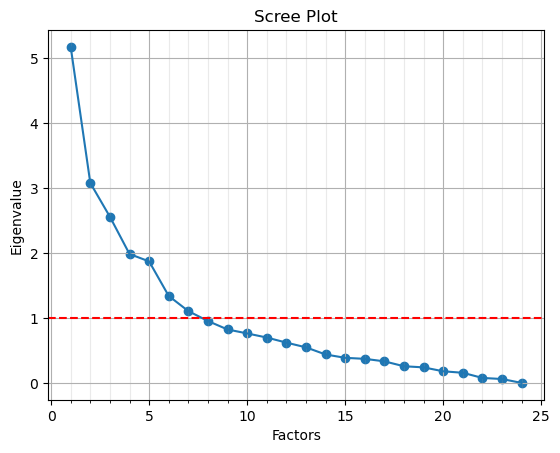

<Figure size 640x480 with 0 Axes>

In [119]:
perform_factor_analysis(DatatSWIHot, n_factors=24)
plt.savefig('Figures/DatatSWIHotcreeplot.png')

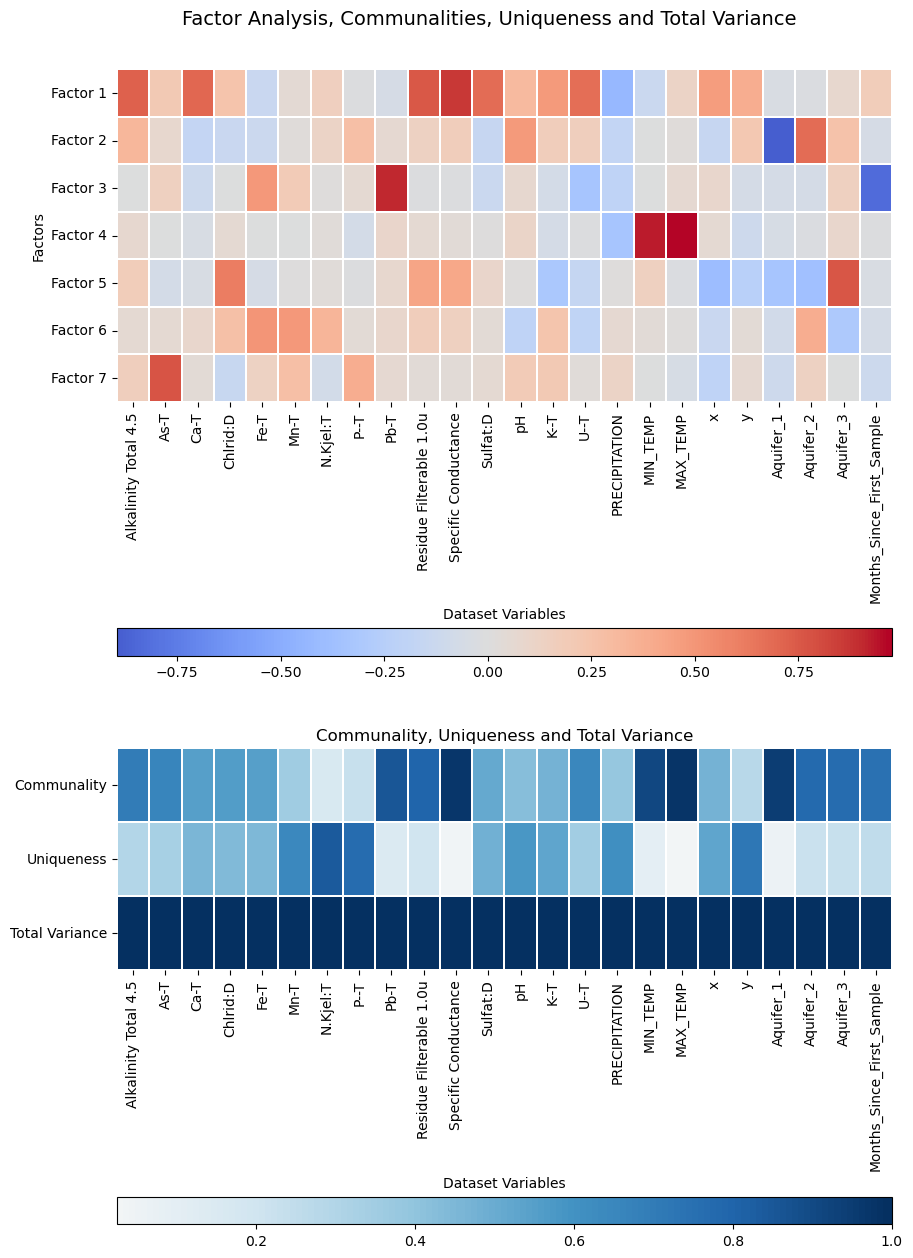

In [123]:
perform_factor_analysis_and_plot(DatatSWIHot, n_factors=7, data_name='DatatSWIHot')

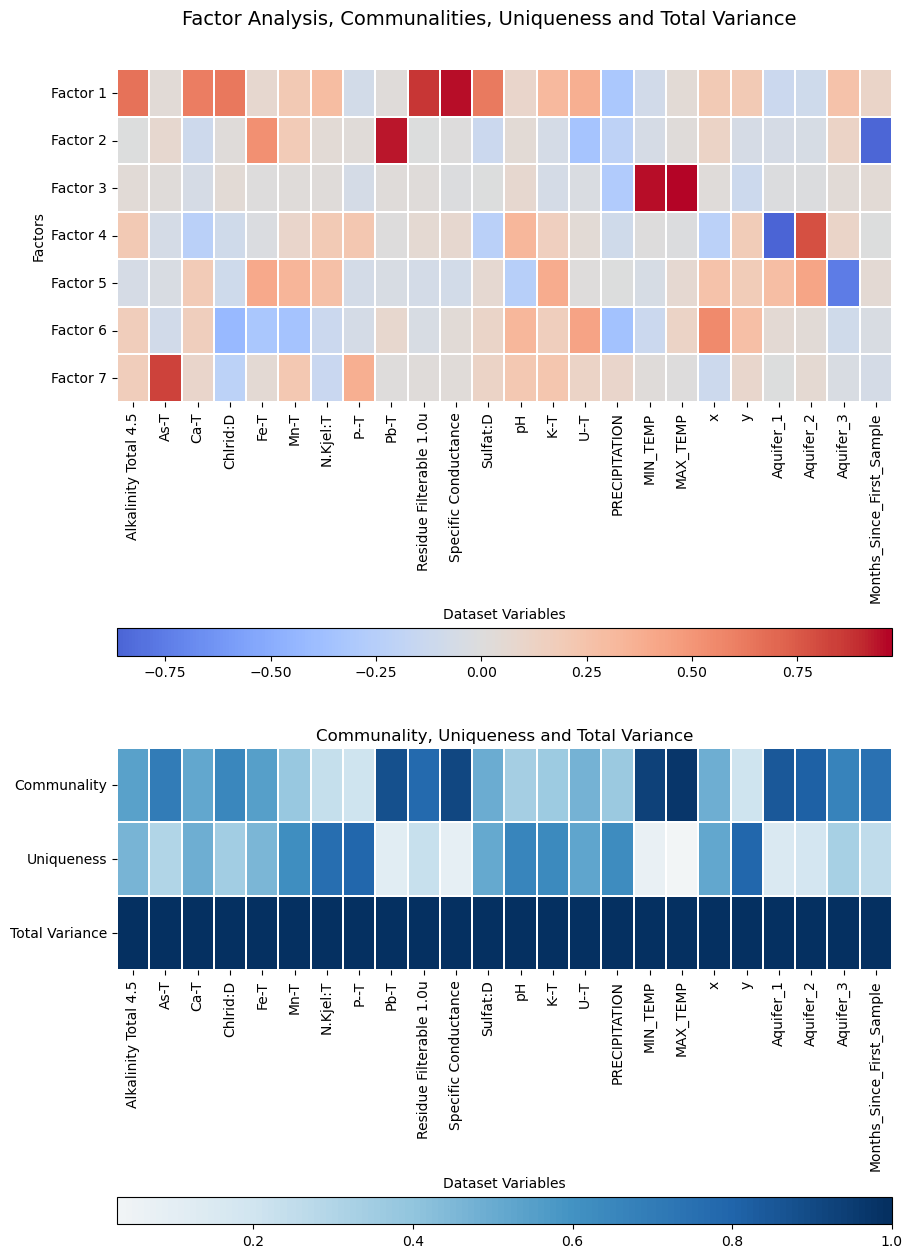

In [146]:
perform_factor_analysis_and_plotOBS(DatatSWIHot, n_factors=7, data_name='DatatSWIHot')

In [113]:
DatatDroughtHot.shape

(530, 24)

In [32]:
analyze_continuous_data(DatatDroughtHot)

Bartlett's test results:
Chi-square value - 6841.228386512576
P-value - 0.0

Kaiser-Meyer-Olkin test results:
Overall MSA - 0.7573510837340478

MSA for each variable:
Alkalinity Total 4.5: 0.8964726534649005
As-T: 0.8180409461555531
Ca-T: 0.7820009455739618
Chlrid:D: 0.7596757411598286
Fe-T: 0.6618473189212615
Mn-T: 0.6621891138375227
N.Kjel:T: 0.7199697459146456
P--T: 0.614228190413656
Pb-T: 0.6521534447027398
Residue Filterable 1.0u: 0.8629593702470945
Specific Conductance: 0.8014794474595538
Sulfat:D: 0.9206381271887444
pH: 0.7233752366971442
K--T: 0.8879453987433503
U--T: 0.8641390935230617
PRECIPITATION: 0.8327411408488038
MIN_TEMP: 0.5068091500391687
MAX_TEMP: 0.5236651520558816
x: 0.5604196860018021
y: 0.6430251795059271
Months_Since_First_Sample: 0.6799642127823029


Number of eigenvalues greater than 1: 6
Eigenvalues:  [5.68184868e+00 3.14893510e+00 2.51495689e+00 1.98024588e+00
 1.80761027e+00 1.22796568e+00 9.46483836e-01 9.08898406e-01
 8.70455957e-01 8.11574019e-01 6.78150391e-01 6.45908526e-01
 4.85059391e-01 4.05057834e-01 3.87799710e-01 3.37554041e-01
 2.96331521e-01 2.39484452e-01 2.14673599e-01 1.56430146e-01
 1.40538199e-01 5.92541353e-02 5.47833383e-02 2.55262814e-15]
Sum of eigenvalues greater than 1: 16.36156249835072
Sum of eigenvalues > 1 / total sum of eigenvalues: 0.6817317707646133


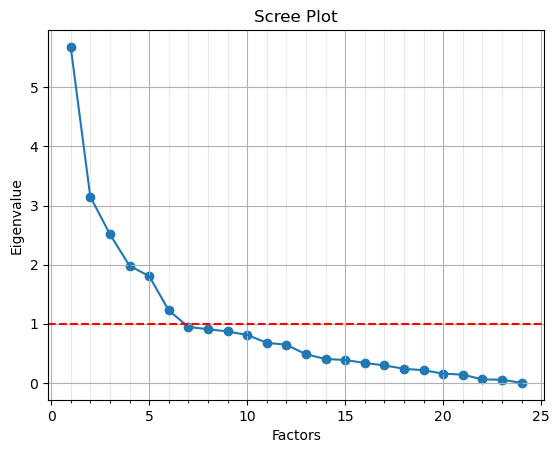

<Figure size 640x480 with 0 Axes>

In [120]:
perform_factor_analysis(DatatDroughtHot, n_factors=24)
plt.savefig('Figures/DatatDroughtHotscreeplot.png')

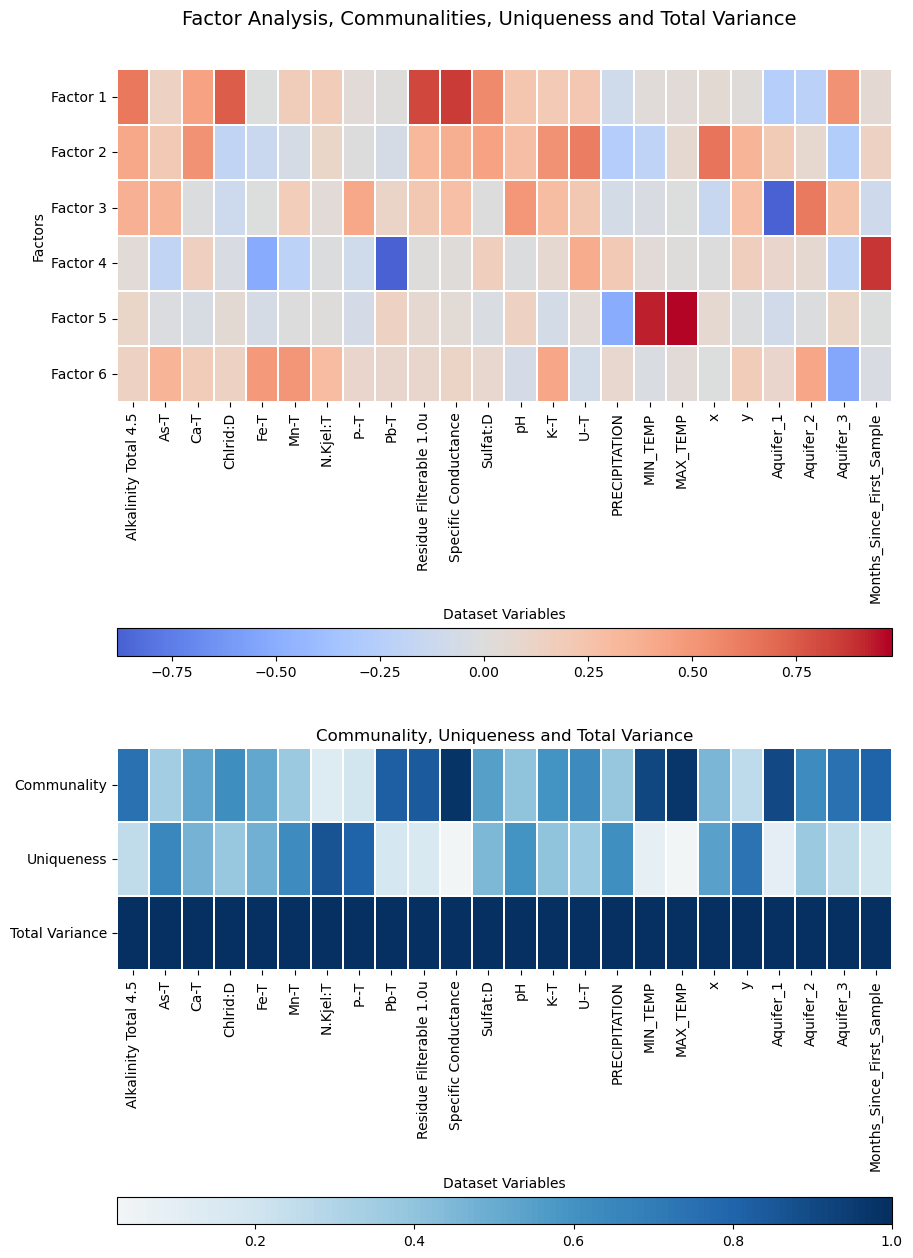

In [124]:
perform_factor_analysis_and_plot(DatatDroughtHot, n_factors=6, data_name='DatatDroughtHot')

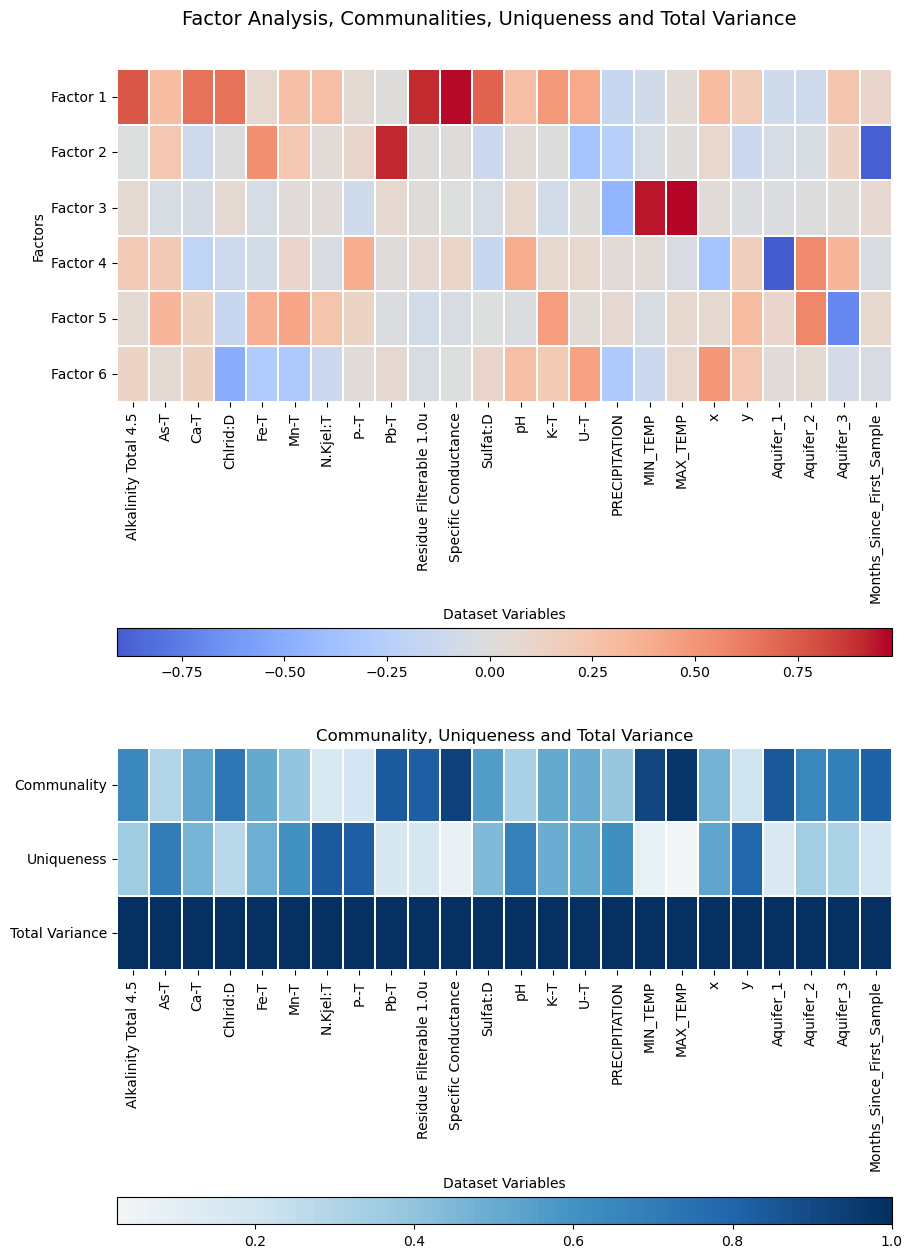

In [147]:
perform_factor_analysis_and_plotOBS(DatatDroughtHot, n_factors=6, data_name='DatatDroughtHot')

In [115]:
DatatFloodHot.shape

(455, 24)

In [33]:
analyze_continuous_data(DatatFloodHot)

Bartlett's test results:
Chi-square value - 5553.470253424557
P-value - 0.0

Kaiser-Meyer-Olkin test results:
Overall MSA - 0.7340322154318789

MSA for each variable:
Alkalinity Total 4.5: 0.8896559273144163
As-T: 0.6458738769342595
Ca-T: 0.8502519374453426
Chlrid:D: 0.6642869084498868
Fe-T: 0.7200581005138321
Mn-T: 0.6133227393150501
N.Kjel:T: 0.6731023485559837
P--T: 0.48679113670412344
Pb-T: 0.606403277028997
Residue Filterable 1.0u: 0.8579621023085604
Specific Conductance: 0.8244940259543307
Sulfat:D: 0.895629584494798
pH: 0.6321989536518609
K--T: 0.7674524884459942
U--T: 0.9004193036007957
PRECIPITATION: 0.7920332999266049
MIN_TEMP: 0.5010716909994535
MAX_TEMP: 0.4925052619171965
x: 0.5586462122642677
y: 0.7381119339857023
Months_Since_First_Sample: 0.6226054443398872


Number of eigenvalues greater than 1: 7
Eigenvalues:  [5.30067069e+00 3.02813313e+00 2.48986367e+00 2.27592134e+00
 1.74676931e+00 1.42178707e+00 1.29070563e+00 9.28593733e-01
 7.95111727e-01 6.80748721e-01 6.35697970e-01 5.52937876e-01
 4.73019229e-01 4.48912050e-01 3.64264370e-01 3.35689745e-01
 3.16850428e-01 2.44176106e-01 2.09839683e-01 1.72282951e-01
 1.35933226e-01 9.30139280e-02 5.90774081e-02 5.45142999e-16]
Sum of eigenvalues greater than 1: 17.553850848851297
Sum of eigenvalues > 1 / total sum of eigenvalues: 0.7314104520354708


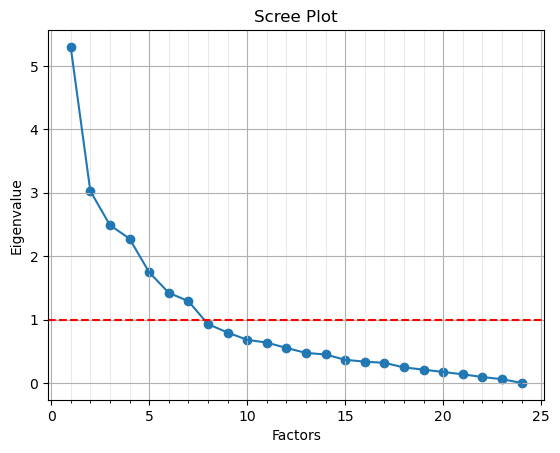

<Figure size 640x480 with 0 Axes>

In [121]:
perform_factor_analysis(DatatFloodHot, n_factors=24)
plt.savefig('Figures/DatatFloodHotscreeplot.png')

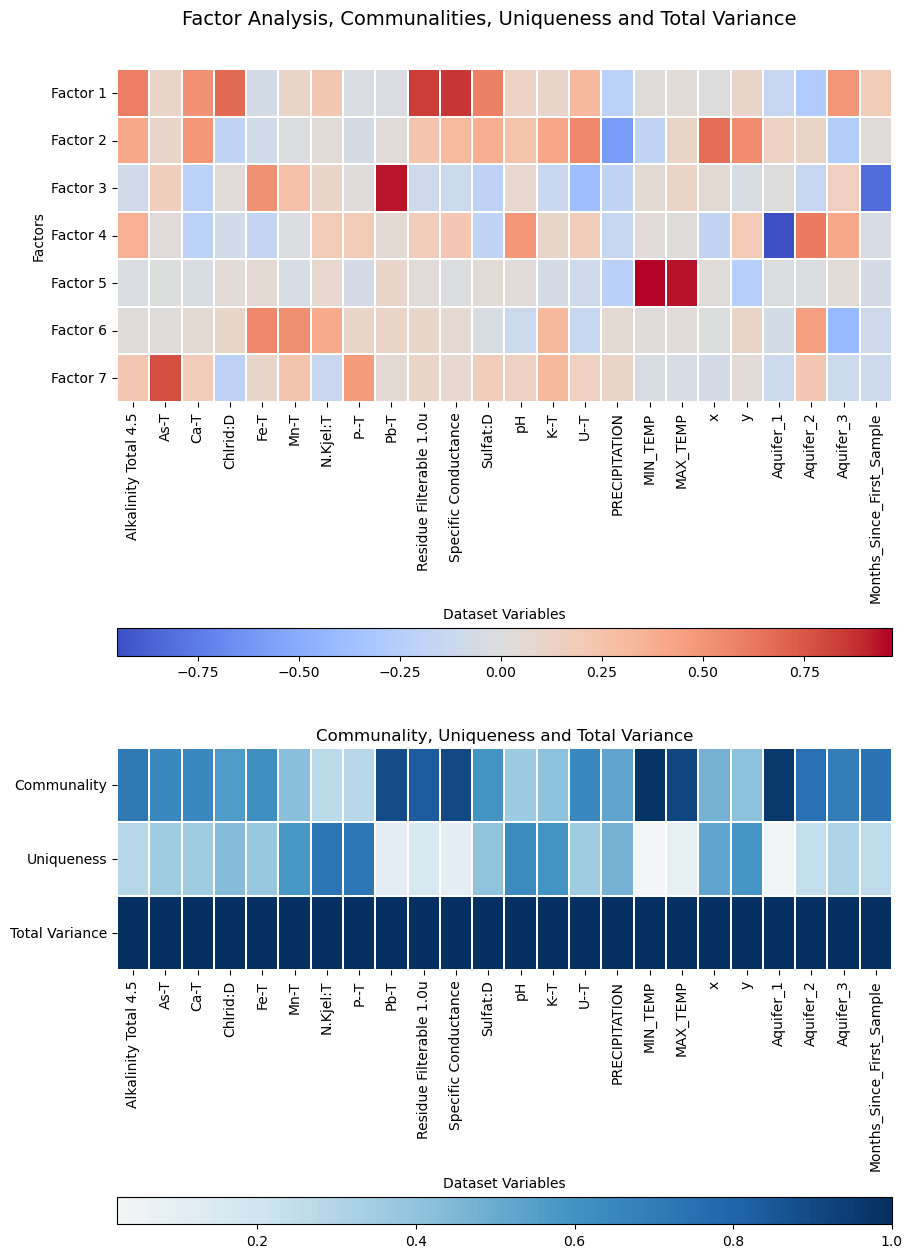

In [125]:
perform_factor_analysis_and_plot(DatatFloodHot, n_factors=7, data_name='DatatFloodHot')

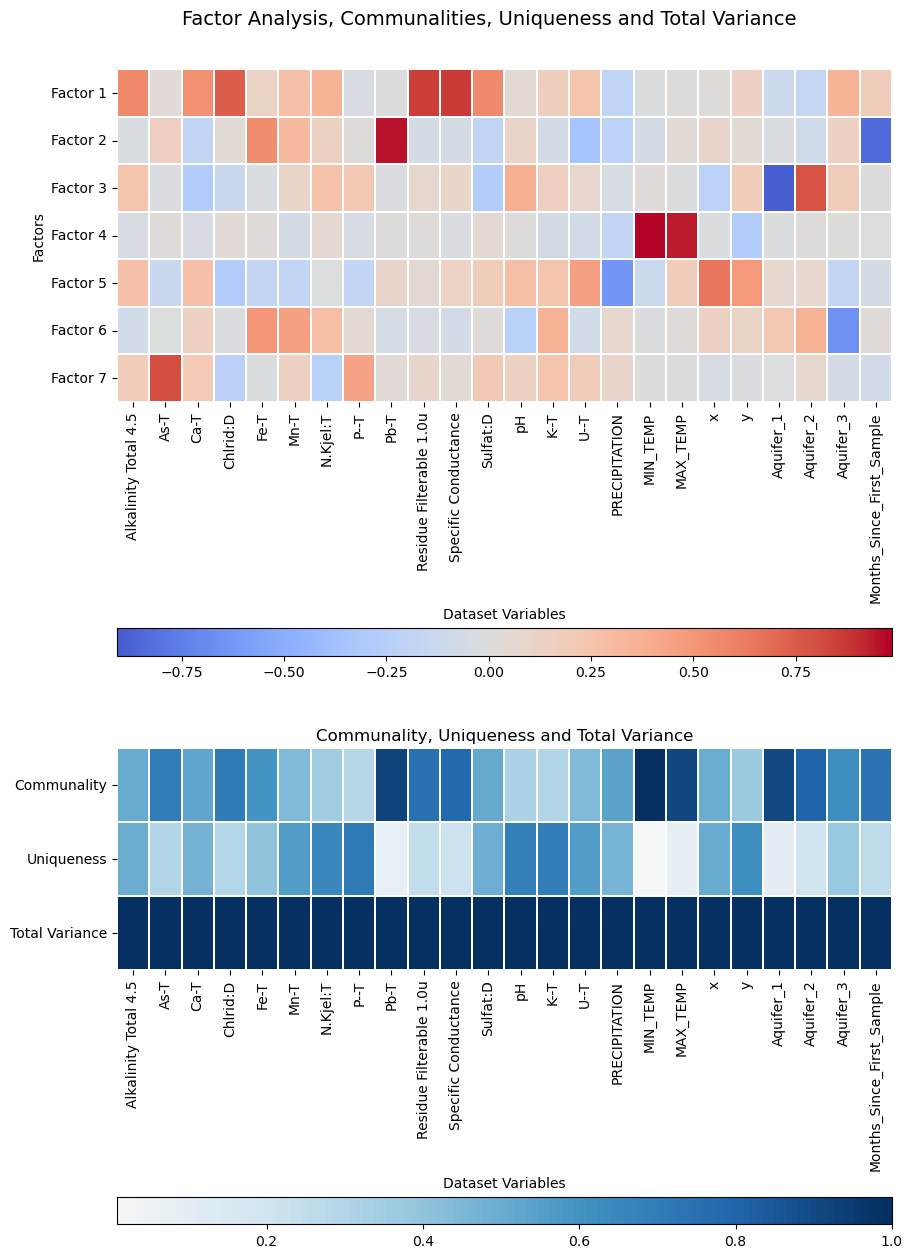

In [148]:
perform_factor_analysis_and_plotOBS(DatatFloodHot, n_factors=7, data_name='DatatFloodHot')

In [117]:
DatatHWHot.shape

(611, 24)

In [118]:
analyze_continuous_data(DatatHWHot)

Bartlett's test results:
Chi-square value - 7255.0377684292425
P-value - 0.0

Kaiser-Meyer-Olkin test results:
Overall MSA - 0.7662128309157982

MSA for each variable:
Alkalinity Total 4.5: 0.9107141054428283
As-T: 0.768198687577022
Ca-T: 0.8107715819720657
Chlrid:D: 0.7585699270642527
Fe-T: 0.6988951577406848
Mn-T: 0.6583511046227228
N.Kjel:T: 0.8048743953158222
P--T: 0.5751167168932624
Pb-T: 0.6367186173147913
Residue Filterable 1.0u: 0.8688708038140605
Specific Conductance: 0.8366852547283534
Sulfat:D: 0.9245274256580505
pH: 0.7060298876052845
K--T: 0.8560784774204127
U--T: 0.8796331338668602
PRECIPITATION: 0.7486936571093323
MIN_TEMP: 0.4885389911165341
MAX_TEMP: 0.48235947297201787
x: 0.6932610958950963
y: 0.7612752255398048
Months_Since_First_Sample: 0.6939589162288787


Number of eigenvalues greater than 1: 7
Eigenvalues:  [ 5.61537957e+00  2.97839801e+00  2.54446186e+00  2.03427683e+00
  1.83260140e+00  1.25595711e+00  1.06272448e+00  8.50617372e-01
  8.14747209e-01  7.73963169e-01  6.51776318e-01  6.20268116e-01
  5.46961129e-01  4.07588238e-01  3.70307608e-01  3.45923941e-01
  3.16317746e-01  2.70001036e-01  2.21774509e-01  1.81817511e-01
  1.46620500e-01  9.04363204e-02  6.70800126e-02 -2.30137821e-15]
Sum of eigenvalues greater than 1: 17.323799265240783
Sum of eigenvalues > 1 / total sum of eigenvalues: 0.7218249693850326


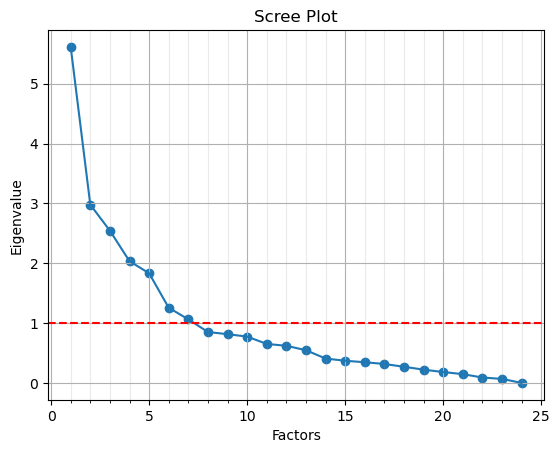

<Figure size 640x480 with 0 Axes>

In [122]:
perform_factor_analysis(DatatHWHot, n_factors=24)
plt.savefig('Figures/DatatHWHotscreeplot.png')

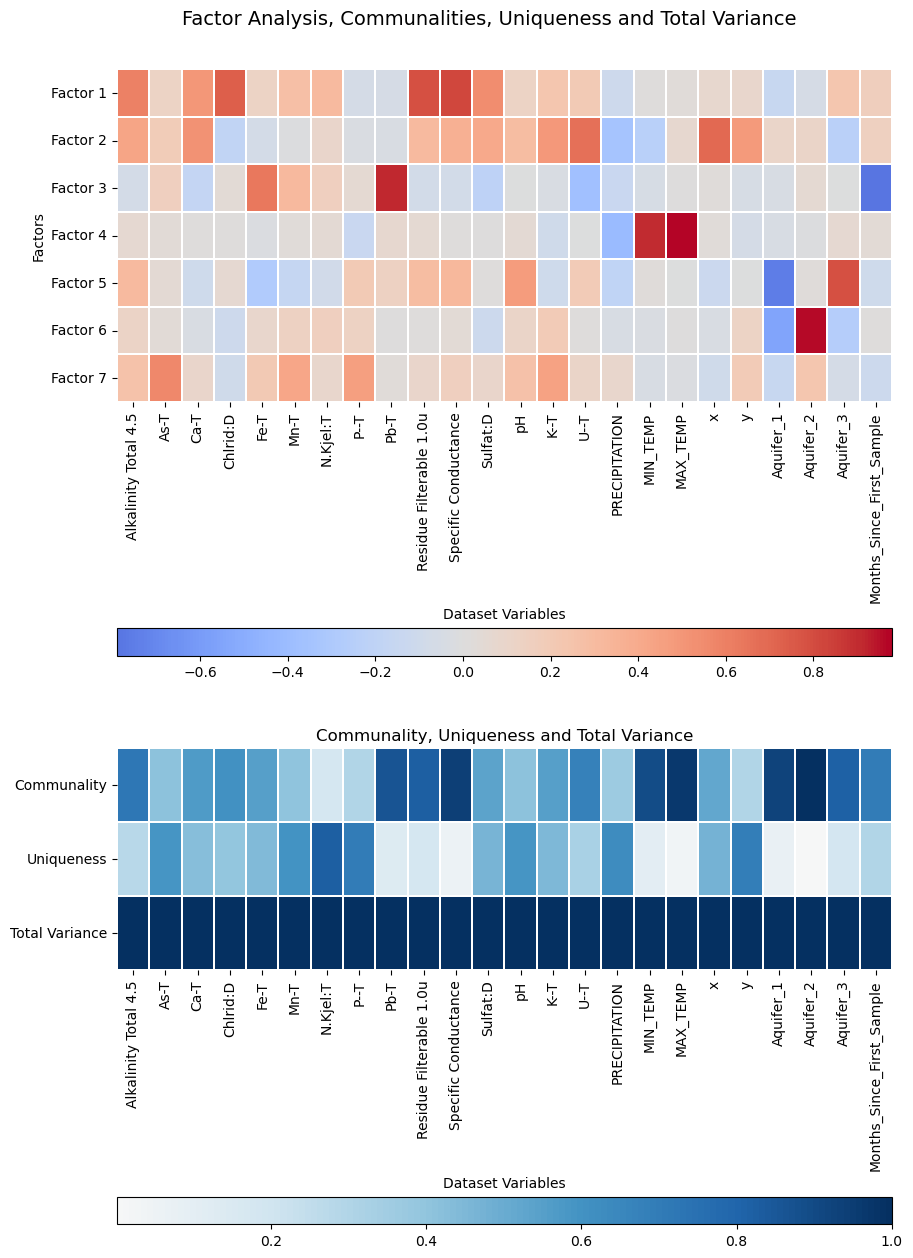

In [126]:
perform_factor_analysis_and_plot(DatatHWHot, n_factors=7, data_name='DatatHWHot')

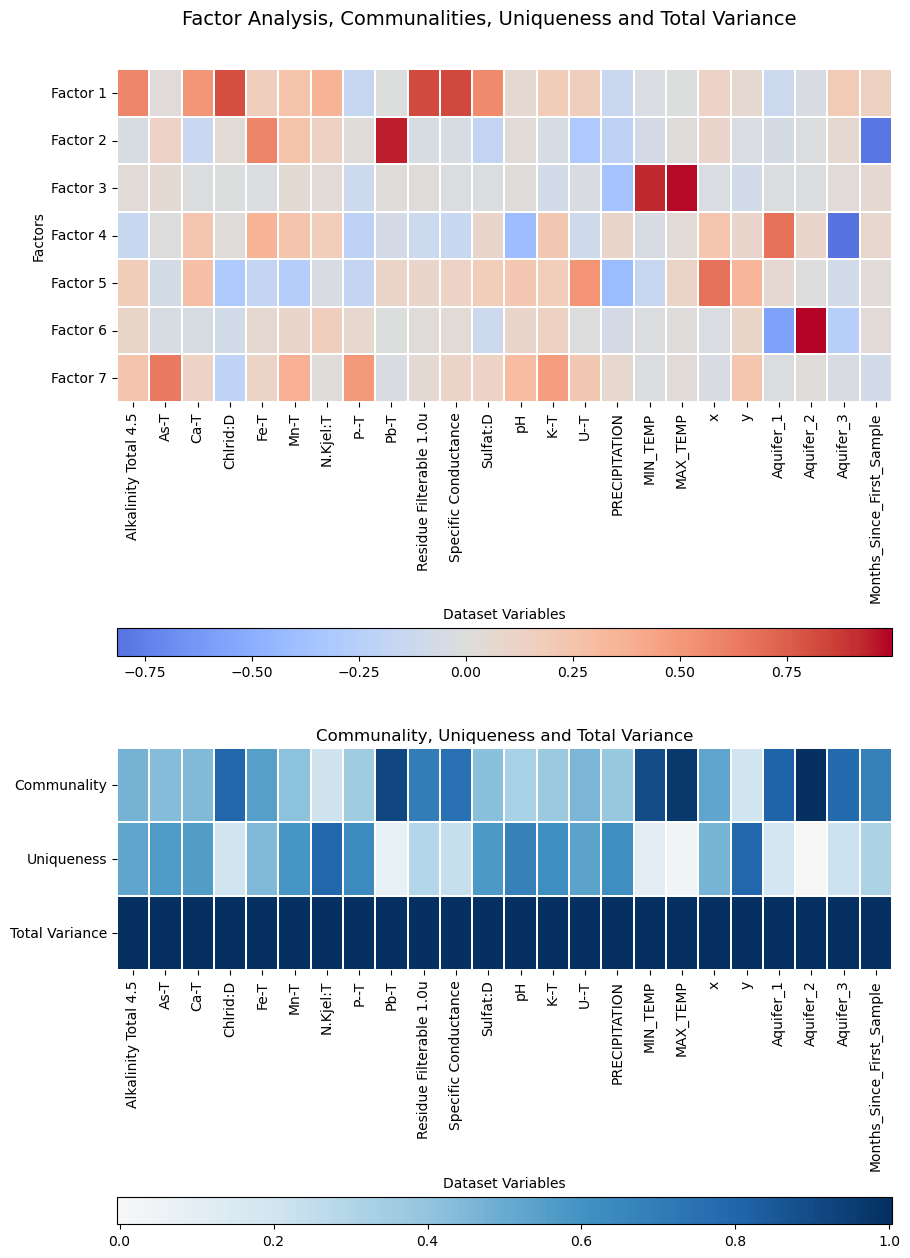

In [149]:
perform_factor_analysis_and_plotOBS(DatatHWHot, n_factors=7, data_name='DatatHWHot')

In [29]:
analyze_continuous_data(DatatMTHot)

Bartlett's test results:
Chi-square value - 8790.954492074476
P-value - 0.0

Kaiser-Meyer-Olkin test results:
Overall MSA - 0.7559998435613221

MSA for each variable:
Alkalinity Total 4.5: 0.9109382028934857
As-T: 0.7514041889295201
Ca-T: 0.8014061955130036
Chlrid:D: 0.7486814069510249
Fe-T: 0.6633568131224767
Mn-T: 0.6145741439086447
N.Kjel:T: 0.7092053184003894
P--T: 0.6203843856636715
Pb-T: 0.621941967375591
Residue Filterable 1.0u: 0.8703653021663368
Specific Conductance: 0.8326271067310439
Sulfat:D: 0.9329867507082705
pH: 0.6972987989316305
K--T: 0.8412318581738101
U--T: 0.8797398161041214
PRECIPITATION: 0.8044678168223266
MIN_TEMP: 0.4872973737695517
MAX_TEMP: 0.4959851182639093
x: 0.5773947936091155
y: 0.6993880716101256
Months_Since_First_Sample: 0.6934768919919254


Number of eigenvalues greater than 1: 7
Eigenvalues:  [5.66247801e+00 2.92549481e+00 2.57885916e+00 1.93954319e+00
 1.78687135e+00 1.32458070e+00 1.09841977e+00 9.06019797e-01
 8.40455209e-01 7.55170732e-01 6.83407296e-01 6.10592007e-01
 5.12716695e-01 4.03558374e-01 3.80342461e-01 3.61882092e-01
 3.20301418e-01 2.42146090e-01 2.17287580e-01 1.77420830e-01
 1.40892103e-01 7.36360972e-02 5.79242233e-02 6.65260543e-16]
Sum of eigenvalues greater than 1: 17.316246996208026
Sum of eigenvalues > 1 / total sum of eigenvalues: 0.7215102915086677


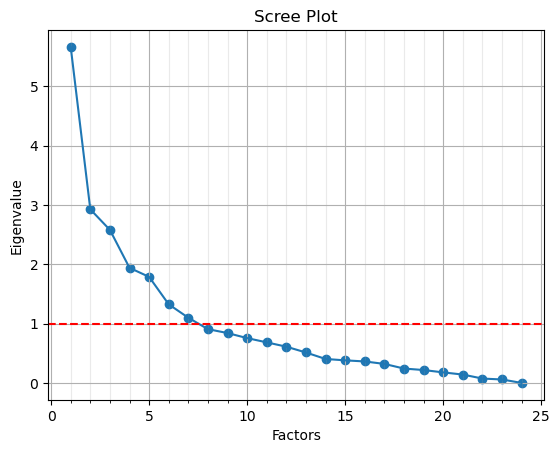

<Figure size 640x480 with 0 Axes>

In [30]:
perform_factor_analysis(DatatMTHot, n_factors=24)
plt.savefig('Figures/DatatMTHotscreeplot.png')

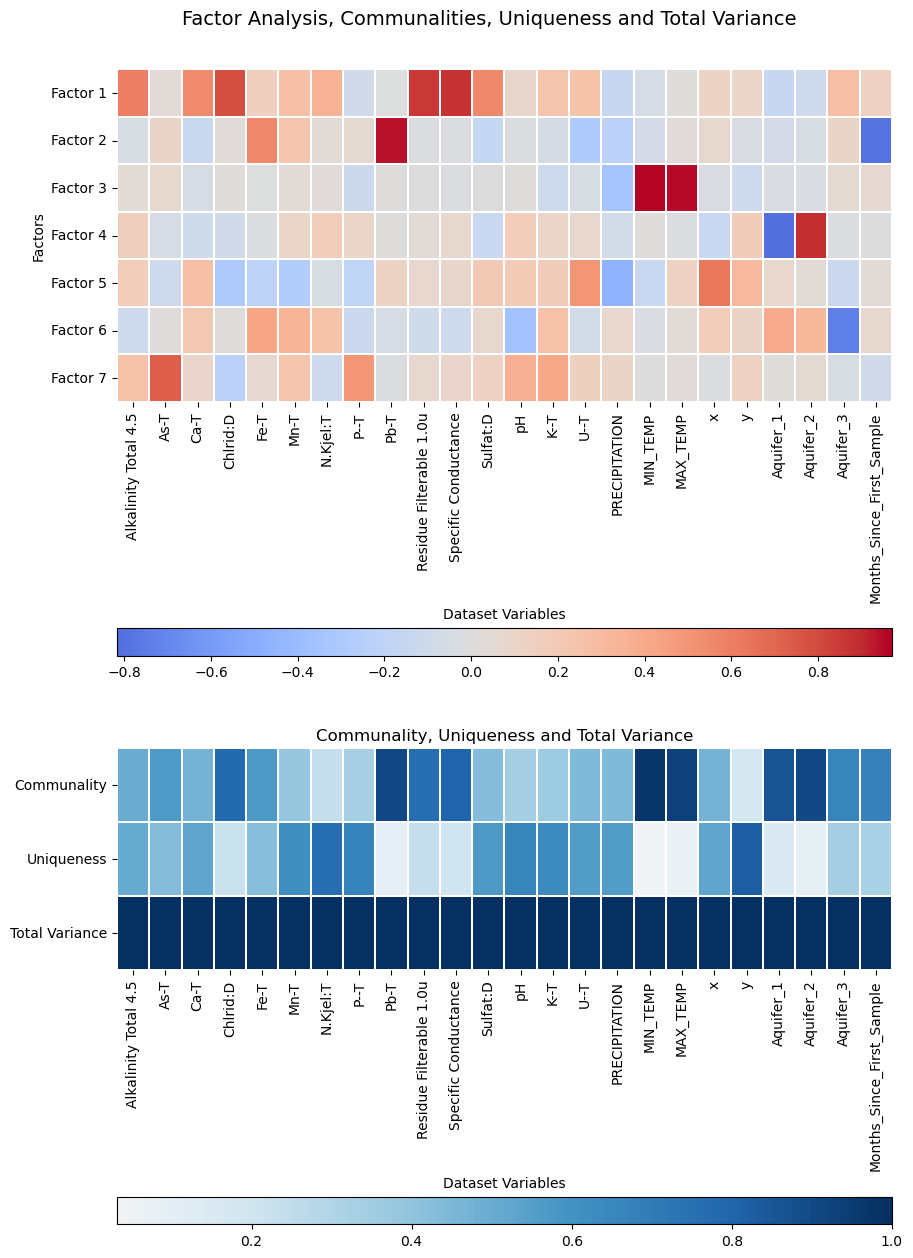

In [31]:
perform_factor_analysis_and_plotOBS(DatatMTHot, n_factors=7, data_name='DatatMTHot')

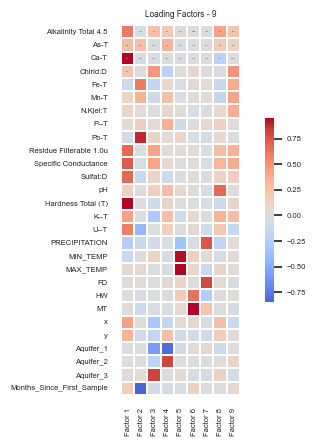

In [93]:
fa2 = FactorAnalyzer(9, rotation="varimax")
fa2.fit(DatatHot)
x_labels = ['Factor ' + str(i) for i in range(1,count+1)]
y_labels = DatatHot.columns.tolist()
sns.set(font_scale=0.5)
plt.title('Loading Factors - ' + str(count))
load = sns.heatmap(fa2.loadings_,cmap="coolwarm", xticklabels = x_labels, yticklabels = y_labels, center=0, square=True, linewidths=.2,cbar_kws={"shrink": 0.5}, annot = True, annot_kws={"fontsize":1})
plt.savefig('Figures/VarimaxFAEG9fulldata.png')

In [95]:

FAmatrixFull9 = pd.DataFrame(fa2.loadings_, index = list(DatatHot.columns), columns = ['Factor 1', 'Factor 2', 'Factor 3', 'Factor 4', 'Factor 5', 'Factor 6', 'Factor 7', 'Factor 8', 'Factor 9'])
FAmatrixFull9.to_csv("Stats/FAmatrixFull9.csv")
FAmatrixFull9.head()

,Factor 1,Factor 2,Factor 3,Factor 4,Factor 5,Factor 6,Factor 7,Factor 8,Factor 9
Alkalinity Total 4.5,0.610885,-0.043961,0.265625,0.219879,0.048148,0.008756,-0.027942,0.435505,0.250072
As-T,0.289810,0.285456,-0.038789,0.343466,-0.023377,-0.025931,0.014077,0.168830,0.125750
Ca-T,0.946411,-0.051258,-0.025767,0.009220,-0.018025,-0.009013,-0.029429,-0.217566,0.008220
Chlrid:D,0.244668,0.012497,0.477078,-0.234921,0.029239,0.083510,0.015933,-0.039094,0.499833
Fe-T,-0.104672,0.598999,-0.179177,0.091283,-0.032676,0.059033,0.039051,-0.121549,0.377563


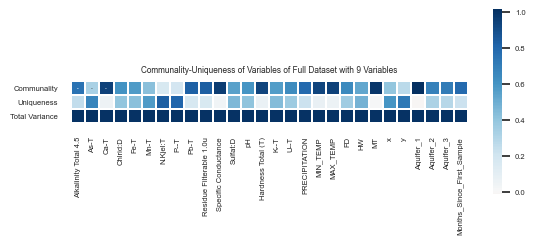

In [97]:
var_check = np.vstack((fa2.get_communalities(), fa2.get_uniquenesses(),np.array(fa2.get_communalities() + fa2.get_uniquenesses()))).tolist()
y_labels = ['Communality','Uniqueness', 'Total Variance']
x_labels = DatatHot.columns.tolist()
sns.set(font_scale=0.5)
plt.title('Communality-Uniqueness of Variables of Full Dataset with 9 Variables')
load = sns.heatmap(var_check,cmap="RdBu", xticklabels = x_labels, yticklabels = y_labels, center=0, square=True, linewidths=.2,cbar_kws={"shrink": 0.5}, annot = True, annot_kws={"fontsize":1})
plt.savefig('Figures/CommunityUniquenessTotalVarFAEG9fulldata.png')

In [113]:
#Hardness, akalinity total, residal non filterable, MT
# factor9, x, y, 'P--t', 'months_since first sample', 
#Redo
#'Residue Filterable 1.0u' is key as below that MSA is <.5. And gives the biggest increase
DropDF4a = ['FD', 'MT', 'HW']
DatatHotOther = DatatHot.drop(DropDF4a, axis=1, errors='ignore')

analyze_continuous_data(DatatHotOther)

Bartlett's test results:
Chi-square value - 14438.990502472905
P-value - 0.0

Kaiser-Meyer-Olkin test results:
Overall MSA - 0.7776421720683113

MSA for each variable:
Alkalinity Total 4.5: 0.9142823072585394
As-T: 0.8221584765107818
Ca-T: 0.7777661512406285
Chlrid:D: 0.7416483763266147
Fe-T: 0.7144605403194564
Mn-T: 0.6630528203448728
N.Kjel:T: 0.7631812835735116
P--T: 0.5832102211433611
Pb-T: 0.6577179397692822
Residue Filterable 1.0u: 0.8837528499277428
Specific Conductance: 0.8406819490564448
Sulfat:D: 0.9350352662420305
pH: 0.7556682239158505
Hardness Total (T): 0.7953616703549944
K--T: 0.8302330833475338
U--T: 0.902921087207996
PRECIPITATION: 0.8166927241447154
MIN_TEMP: 0.49204216086746494
MAX_TEMP: 0.498163225045712
x: 0.6415134906384121
y: 0.7308621958102474
Months_Since_First_Sample: 0.7074978213454627
